# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [2]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple, MerlinTunableEntropy
from src.pde     import HeatEquation, WaveEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import hilbert_space_dimension, quantum_outputsize_for_param_match, find_matching_hidden_readout

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [3]:
#FREQUENCIES = [0.5, 1.0, 1.5, 2, 2.5, 3, 3.5, 4.0, 4.5]
FREQUENCIES = [3, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0]
#SEEDS = [42]#, 666, 69, 67, 13]
SEEDS = [120]

In [4]:
FEATURE_SIZES_guess = [3]#[2,4,8,16]
FEATURE_SIZE, HIDDEN_READOUT = find_matching_hidden_readout(feature_sizes=FEATURE_SIZES_guess, ranges=[1,100])

#print(FEATURE_SIZE)
#print(HIDDEN_READOUT)
#select smallest
FEATURE_SIZE = FEATURE_SIZE[0]
HIDDEN_READOUT = HIDDEN_READOUT[0]
QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))
print(f"FEATURE_SIZE={FEATURE_SIZE}, HIDDEN_READOUT={HIDDEN_READOUT}, QUANTUM_OUTPUT_SIZE={QUANTUM_OUTPUT_SIZE}")

[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
FEATURE_SIZE=3, HIDDEN_READOUT=4, QUANTUM_OUTPUT_SIZE=8


In [4]:
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for freq in FREQUENCIES:
    #pde = HeatEquation(freq=freq)
    pde = WaveEquation(freq=freq,c=0.5)
    print(f"\n{'='*60}\nfreq = {freq}")
    seed_results = {"classical": [], "qpinn_weights": []}
    for i,seed in enumerate(SEEDS):
        # --- QPINN ---
#        qpinn = MerlinHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
#        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

        # --- Classical ---
        classical = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = pde).to(device)
        train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
        seed_results["classical"].append(metrics["rel_l2"])
        
        print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        # --- QPINN WEIGHTS ---
        qpinn_weights = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=pde).to(device)
        train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed, epochs=600)
        metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
        seed_results["qpinn_weights"].append(metrics["rel_l2"])
        print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
    
    sweep_results["classical"].append({"frequency": freq, "rel_l2": seed_results["classical"]})
    sweep_results["qpinn_weights"].append({"frequency": freq, "rel_l2": seed_results["qpinn_weights"]})



freq = 3
Parameters — total: 177  trainable: 177

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 2.5089e+02 | PDE: 2.46e+02 | Cons: 4.43e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.0s
Epoch   100/600 | Loss: 2.5521e+02 | PDE: 2.51e+02 | Cons: 4.45e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.3s
Epoch   200/600 | Loss: 2.5769e+02 | PDE: 2.54e+02 | Cons: 3.97e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.6s
Epoch   300/600 | Loss: 2.3835e+02 | PDE: 2.34e+02 | Cons: 4.77e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 0.9s
Epoch   400/600 | Loss: 2.5594e+02 | PDE: 2.52e+02 | Cons: 4.12e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.3s
Epoch   500/600 | Loss: 2.6214e+02 | PDE: 2.58e+02 | Cons: 3.98e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.6s
Epoch   600/600 | Loss: 2.5353e+02 | PDE: 2.49e+02 | Cons: 4.53e+01 | IC: 0.00e+00 | BC: 5.69e-16 | Time: 1.9s

Done — 1.9s total
Evaluating on 60×60 grid …
  Relative L2 : 2.1197e+00
  MAE         : 7.7894e-01
  Max abs err : 2.

KeyboardInterrupt: 

IndexError: list index out of range

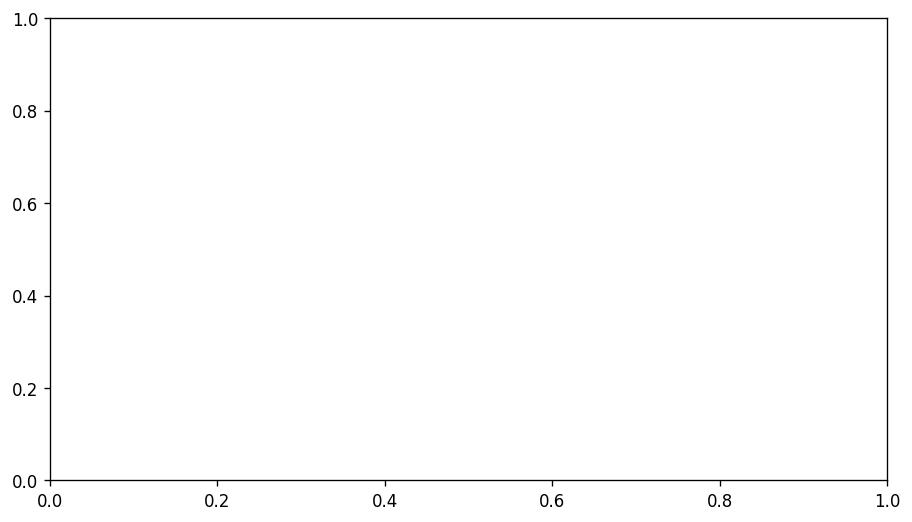

In [16]:
%reload_ext autoreload
plot_frequency_sweep(
    sweep_results,
    save_path = "../figures/fourier_demo/freq_sweep.png",
    show      = True,
)

## 2 - Train both models with same frequency and compare

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt


def compute_quantum_spectrum(model, feature_index=0,
                             n_points=2048,
                             x_range=(-np.pi,np.pi),
                             threshold=1e-6):
    """
    Analyse spectrale du bloc quantique.

    Retour:
        freqs : fréquences Fourier
        spectrum : matrice [n_fock_states, n_freqs]
    """

    device = next(model.parameters()).device

    x_values = np.linspace(
        x_range[0],
        x_range[1],
        n_points,
        endpoint=False
    )

    amplitudes = []

    model.eval()

    with torch.no_grad():

        for x in x_values:

            # input du feature map
            xt = torch.zeros((1, 2), device=device)

            # on injecte x dans la première variable
            xt[0, 0] = x

            # feature map
            z = model.feature_map(xt)

            # sortie quantique uniquement
            q_amp = model.quantum(z)

            # (n_fock,)
            q_amp = q_amp.squeeze(0).cpu().numpy()

            amplitudes.append(q_amp)


    # 
    # amplitudes :
    #
    # shape = (n_points, n_fock_states)
    #
    amplitudes = np.asarray(amplitudes)


    n_fock = amplitudes.shape[1]


    # FFT selon x
    fft_amp = np.fft.fft(amplitudes, axis=0)

    # fréquences associées
    freqs = np.fft.fftfreq(
        n_points,
        d=(x_range[1]-x_range[0])/n_points
    )

    # on recentre
    fft_amp = np.fft.fftshift(fft_amp, axes=0)
    freqs = np.fft.fftshift(freqs)


    #
    # matrice spectrale
    #
    spectrum = np.abs(fft_amp).T

    # normalisation
    spectrum /= spectrum.max()


    # suppression des petits termes
    spectrum[spectrum < threshold] = 0


    return freqs, spectrum

def compute_pqc_only_spectrum(model, n_points=2048):
    """
    Corrected version of compute_pqc_only_spectrum.

    Injects x into the FIRST slot of EVERY encoding layer's chunk,
    not just z[0,0]. With n_encoding_layers=L, z has shape
    (1, feature_size * L), split into L consecutive chunks of size
    feature_size, one per angle-encoding pass. Only setting z[0,0]
    leaves layers 2..L at a zero angle (identity gate), so re-uploading
    was never actually being exercised for L > 1 in the original version.
    """
    device = next(model.parameters()).device

    xs = np.linspace(-np.pi, np.pi, n_points, endpoint=False)

    amplitudes = []

    model.eval()
    with torch.no_grad():
        for x in xs:
            z = torch.zeros(
                (1, model.feature_size * model.n_encoding_layers),
                device=device
            )

            # inject x into the first slot of every layer's chunk
            for l in range(model.n_encoding_layers):
                z[0, l * model.feature_size] = x

            q_amp = model.quantum(z)
            amplitudes.append(q_amp.squeeze(0).cpu().numpy())

    amplitudes = np.array(amplitudes)

    #####
    plt.figure()
    for j in range(min(5, amplitudes.shape[1])):
        plt.plot(xs, amplitudes[:, j].real, label=f"state {j}")
    plt.legend()
    plt.title("Re(amplitude) vs x — all layers driven")
    plt.show()
    ######

    spectrum = np.abs(
        np.fft.fftshift(np.fft.fft(amplitudes, axis=0), axes=0)
    ).T

    freqs = np.fft.fftshift(
        np.fft.fftfreq(n_points, d=2 * np.pi / n_points)
    )

    return freqs, spectrum

def plot_spectrum(freqs, spectrum, title="Quantum spectrum"):

    plt.figure(figsize=(10,6))

    plt.imshow(
        spectrum,
        aspect="auto",
        extent=[
            freqs[0],
            freqs[-1],
            0,
            spectrum.shape[0]
        ],
        origin="lower"
    )

    plt.xlabel("Fourier frequency k")
    plt.ylabel("Fock state index j")
    plt.xlim((-np.pi,np.pi))

    plt.colorbar(label="|FFT amplitude|")

    plt.title(title)

    plt.show()

def compute_pqc_only_spectrum_2d(model, n_points=128):
    device = next(model.parameters()).device
    xs = np.linspace(-np.pi, np.pi, n_points, endpoint=False)
    ts = np.linspace(-np.pi, np.pi, n_points, endpoint=False)  # or pde.t_min/t_max range

    amplitudes = np.zeros((n_points, n_points, model.quantum.output_size), dtype=complex)

    model.eval()
    with torch.no_grad():
        for it, t in enumerate(ts):
            for ix, x in enumerate(xs):
                z = torch.zeros((1, model.feature_size * model.n_encoding_layers), device=device)
                for l in range(model.n_encoding_layers):
                    z[0, l*model.feature_size + 0] = x
                    z[0, l*model.feature_size + 1] = t   # second encoded slot carries t
                q_amp = model.quantum(z)
                amplitudes[it, ix] = q_amp.squeeze(0).cpu().numpy()

    # 2D FFT over (t, x) axes jointly
    spectrum_2d = np.fft.fftshift(np.fft.fft2(amplitudes, axes=(0,1)), axes=(0,1))
    kx = np.fft.fftshift(np.fft.fftfreq(n_points, d=2*np.pi/n_points)) * 2*np.pi
    kt = np.fft.fftshift(np.fft.fftfreq(n_points, d=2*np.pi/n_points)) * 2*np.pi
    return kx, kt, np.abs(spectrum_2d)

In [6]:
import numpy as np
import torch
from itertools import combinations


# ---------------------------------------------------------------------
# 1. Enumerate the Fock basis for a fixed (n_modes, n_photons) sector,
#    using stars-and-bars, in a well-defined canonical order.
# ---------------------------------------------------------------------
def enumerate_fock_states(n_modes, n_photons):
    """
    All occupation-number tuples (n_0, ..., n_{n_modes-1}) with
    sum(n_i) == n_photons, indistinguishable bosons.

    Ordering: standard "stars and bars" via combinations of bar
    positions, yielding a fixed canonical order. This may or may not
    match Merlin/Perceval's internal ordering -- see verify_basis_order().
    """
    states = []
    # place n_photons stars and (n_modes-1) bars in a line;
    # choose positions of bars among n_photons+n_modes-1 slots
    total_slots = n_photons + n_modes - 1
    for bar_positions in combinations(range(total_slots), n_modes - 1):
        occ = []
        prev = -1
        stars_seen = 0
        bars = list(bar_positions)
        idx = 0
        count = 0
        # walk the slots, counting stars between consecutive bars
        boundaries = [-1] + bars + [total_slots]
        for k in range(len(boundaries) - 1):
            n_stars = (boundaries[k+1] - boundaries[k] - 1)
            occ.append(n_stars)
        states.append(tuple(occ))
    return states


def get_basis_from_model(model):
    """
    Authoritative Fock basis: pulled directly from the QuantumLayer,
    guaranteed to match the amplitude vector's index order.
    """
    keys = model.quantum.output_keys
    # normalize to plain tuples of ints regardless of exact object type
    basis = [tuple(int(n) for n in state) for state in keys]
    return basis


def von_neumann_entropy_from_amplitudes(amplitudes, basis_states,
                                         modes_A, eps=1e-12):
    """
    amplitudes   : complex array, shape (n_fock,)
    basis_states : list of tuples, SAME ORDER as amplitudes
                   (from model.quantum.output_keys)
    modes_A      : list of mode indices forming subsystem A
    """
    n_modes = len(basis_states[0])
    modes_B = [m for m in range(n_modes) if m not in modes_A]

    A_configs, B_configs = {}, {}

    def sub(state, modes):
        return tuple(state[m] for m in modes)

    for state in basis_states:
        a_cfg, b_cfg = sub(state, modes_A), sub(state, modes_B)
        A_configs.setdefault(a_cfg, len(A_configs))
        B_configs.setdefault(b_cfg, len(B_configs))

    M = np.zeros((len(A_configs), len(B_configs)), dtype=complex)
    for amp, state in zip(amplitudes, basis_states):
        i, j = A_configs[sub(state, modes_A)], B_configs[sub(state, modes_B)]
        M[i, j] = amp

    norm = np.sum(np.abs(M) ** 2)
    if not np.isclose(norm, 1.0, atol=1e-4):
        print(f"WARNING: |psi|^2 = {norm:.6f} -- something is still off.")

    rho_A = M @ M.conj().T
    rho_A = rho_A / np.trace(rho_A).real

    eigvals = np.clip(np.linalg.eigvalsh(rho_A).real, eps, None)
    eigvals = eigvals[eigvals > eps]
    return -np.sum(eigvals * np.log(eigvals))


def compute_entropy_curve(model, n_points=512, x_range=(-3.14, 3.14)):
    device = next(model.parameters()).device

    basis = get_basis_from_model(model)
    n_modes = len(basis[0])
    modes_A = list(range(model.feature_size))
    modes_B = [m for m in range(n_modes) if m not in modes_A]

    A_configs, B_configs = set(), set()
    for state in basis:
        A_configs.add(tuple(state[m] for m in modes_A))
        B_configs.add(tuple(state[m] for m in modes_B))
    dim_A, dim_B = len(A_configs), len(B_configs)
    S_max = np.log(min(dim_A, dim_B))
    print(f"n_modes={n_modes}, n_photons={model.quantum.n_photons}, "
          f"dim_A={dim_A}, dim_B={dim_B}, S_max={S_max:.4f} nats")

    x_values = np.linspace(x_range[0], x_range[1], n_points, endpoint=False)
    entropies = []

    model.eval()
    with torch.no_grad():
        for x in x_values:
            xt = torch.zeros((1, 2), device=device)
            xt[0, 0] = x
            z = model.feature_map(xt)
            q_amp = model.quantum(z).squeeze(0).cpu().numpy()
            entropies.append(
                von_neumann_entropy_from_amplitudes(q_amp, basis, modes_A)
            )

    return x_values, np.array(entropies), S_max

In [7]:
FREQUENCY = 2

In [8]:

#ref_pde = HeatEquation(freq=FREQUENCY)
ref_pde = WaveEquation(freq=FREQUENCY, c=1.0)
nepochs=3000

In [11]:
#qpinn_weights_ref = MerlinTunableEntropy(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT+2, pde=ref_pde, n_encoding_layers=3).to(device)
#history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = nepochs)

# Classical
classical_ref = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT+2, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = ref_pde).to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = nepochs)

# QPINN
qpinn_ref = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT+2, pde=ref_pde).to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = nepochs)





Parameters — total: 199  trainable: 199

Training for 3000 epochs on cpu  (dtype=torch.float32)
Epoch     1/3000 | Loss: 5.0586e+00 | PDE: 3.17e-04 | Cons: 1.13e-01 | IC: 5.00e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch    50/3000 | Loss: 3.4664e+00 | PDE: 4.39e-03 | Cons: 8.66e-01 | IC: 3.03e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch   100/3000 | Loss: 2.8496e+00 | PDE: 5.40e-02 | Cons: 2.21e+00 | IC: 1.69e-01 | BC: 0.00e+00 | Time: 0.2s
Epoch   150/3000 | Loss: 2.7364e+00 | PDE: 1.70e-01 | Cons: 1.90e+00 | IC: 1.62e-01 | BC: 0.00e+00 | Time: 0.3s
Epoch   200/3000 | Loss: 2.5736e+00 | PDE: 1.68e-01 | Cons: 2.07e+00 | IC: 1.37e-01 | BC: 0.00e+00 | Time: 0.4s
Epoch   250/3000 | Loss: 2.2283e+00 | PDE: 1.52e-01 | Cons: 1.92e+00 | IC: 1.12e-01 | BC: 0.00e+00 | Time: 0.5s
Epoch   300/3000 | Loss: 2.1329e+00 | PDE: 1.73e-01 | Cons: 1.72e+00 | IC: 1.10e-01 | BC: 0.00e+00 | Time: 0.6s
Epoch   350/3000 | Loss: 1.8422e+00 | PDE: 1.87e-01 | Cons: 1.54e+00 | IC: 8.85e-02 | BC: 0.00e+00 | Time: 0.7s
Epoch   

KeyboardInterrupt: 

In [9]:
import itertools
import numpy as np
import torch
import matplotlib.pyplot as plt


def run_readout_bottleneck_sweep(
    layers_list,
    hidden_readout_list,
    feature_size,
    pde,
    epochs=1000,
    n_seeds=1,
    device=None,
):
    """
    Joint sweep over (n_encoding_layers, hidden_readout) to test whether
    readout MLP capacity is the bottleneck preventing the model from
    exploiting the extra spectral bandwidth unlocked by more encoding layers.

    Hypothesis being tested:
        If HIDDEN_READOUT is the bottleneck, rel_l2 should improve along the
        hidden_readout axis specifically for large L, while staying roughly
        flat across hidden_readout for L=1 (small L already has a narrow
        enough comb that a small readout can use it fully).

    Returns:
        results: dict[(L, hidden_readout)] -> list of rel_l2 (one per seed)
        also prints a summary table and plots a heatmap.
    """
    results = {}

    for L, hr in itertools.product(layers_list, hidden_readout_list):
        rel_l2s = []
        for seed in range(n_seeds):
            torch.manual_seed(seed)
            np.random.seed(seed)

            model = MerlinTunableEntropy(
                feature_size=feature_size,
                hidden_readout=hr,
                n_encoding_layers=L,
                pde=pde,
            ).to(device)

            train(
                model=model,
                pde=pde,
                epochs=epochs,
                seed=seed,
                log_every=50,  # only log start/end, keep output short
            )

            metrics, U_pred, U_true, x_grid, t_grid = evaluate(
                model=model, pde=pde, device=device
            )
            rel_l2s.append(metrics["rel_l2"])

            print(f"L={L:2d}  hidden_readout={hr:3d}  seed={seed}  "
                  f"rel_l2={metrics['rel_l2']:.4e}")

        results[(L, hr)] = rel_l2s

    return results


def plot_readout_bottleneck_heatmap(results, layers_list, hidden_readout_list,
                                     title="rel_l2 vs (n_encoding_layers, hidden_readout)"):
    """
    Heatmap of mean rel_l2 across the (L, hidden_readout) grid.
    Log-color-scale since rel_l2 often spans orders of magnitude.
    """
    grid = np.zeros((len(layers_list), len(hidden_readout_list)))

    for i, L in enumerate(layers_list):
        for j, hr in enumerate(hidden_readout_list):
            grid[i, j] = np.mean(results[(L, hr)])

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(
        np.log10(grid),
        aspect="auto",
        origin="lower",
        cmap="viridis_r",  # darker = better (lower error) if reversed cmap
        extent=[0, len(hidden_readout_list), 0, len(layers_list)],
    )
    ax.set_xticks(np.arange(len(hidden_readout_list)) + 0.5)
    ax.set_xticklabels(hidden_readout_list)
    ax.set_yticks(np.arange(len(layers_list)) + 0.5)
    ax.set_yticklabels(layers_list)
    ax.set_xlabel("hidden_readout")
    ax.set_ylabel("n_encoding_layers")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="log10(rel_l2)")

    # annotate cells with actual values
    for i, L in enumerate(layers_list):
        for j, hr in enumerate(hidden_readout_list):
            ax.text(j + 0.5, i + 0.5, f"{grid[i,j]:.2e}",
                     ha="center", va="center", fontsize=8, color="white")

    fig.tight_layout()
    plt.show()

    return grid


def plot_readout_bottleneck_lines(results, layers_list, hidden_readout_list):
    """
    Line plot: rel_l2 vs hidden_readout, one line per L.
    Makes the interaction effect (does increasing hidden_readout help
    MORE for large L than for small L) visually explicit.
    """
    fig, ax = plt.subplots(figsize=(8, 5))

    for L in layers_list:
        means = [np.mean(results[(L, hr)]) for hr in hidden_readout_list]
        ax.semilogy(hidden_readout_list, means, marker="o", label=f"L={L}")

    ax.set_xlabel("hidden_readout")
    ax.set_ylabel("rel_l2 (log scale)")
    ax.set_title("Effect of readout capacity, per encoding-layer depth")
    ax.legend()
    ax.grid(True, alpha=0.3, which="both")
    fig.tight_layout()
    plt.show()

In [10]:
layers_list = [1, 2, 4]
hidden_readout_list = [2, 8, 12]

results = run_readout_bottleneck_sweep(
    layers_list=layers_list,
    hidden_readout_list=hidden_readout_list,
    feature_size=FEATURE_SIZE,
    pde=ref_pde,
    epochs=3000,
    n_seeds=1,   # a few seeds recommended given training noise you've observed
    device=device,
)

plot_readout_bottleneck_heatmap(results, layers_list, hidden_readout_list)
plot_readout_bottleneck_lines(results, layers_list, hidden_readout_list)

Parameters — total: 151  trainable: 151

Training for 3000 epochs on cpu  (dtype=torch.float32)
Epoch     1/3000 | Loss: 5.8053e+00 | PDE: 1.32e-06 | Cons: 7.24e-01 | IC: 5.44e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/3000 | Loss: 5.4167e+00 | PDE: 2.34e-03 | Cons: 2.96e-02 | IC: 5.40e-01 | BC: 0.00e+00 | Time: 2.0s


KeyboardInterrupt: 

In [11]:
import itertools
import numpy as np
import torch
import matplotlib.pyplot as plt


def run_feature_size_by_layers_sweep(
    feature_size_list,
    layers_list,
    hidden_readout,
    pde,
    epochs=1000,
    n_seeds=1,
    device=None,
):
    """
    Joint sweep over (feature_size, n_encoding_layers) at fixed hidden_readout.

    Returns:
        results: dict[(fs, L)] -> list of rel_l2 (one per seed)
    """
    results = {}

    for fs, L in itertools.product(feature_size_list, layers_list):
        rel_l2s = []
        for seed in range(n_seeds):
            torch.manual_seed(seed)
            np.random.seed(seed)

            model = MerlinTunableEntropy(
                feature_size=fs,
                hidden_readout=hidden_readout,
                n_encoding_layers=L,
                pde=pde,
            ).to(device)

            train(
                model=model,
                pde=pde,
                epochs=epochs,
                seed=seed,
                log_every=50,
            )

            metrics, U_pred, U_true, x_grid, t_grid = evaluate(
                model=model, pde=pde, device=device
            )
            rel_l2s.append(metrics["rel_l2"])

            n_photons = getattr(model.quantum, "n_photons", None)
            print(f"feature_size={fs:2d}  n_photons={n_photons}  L={L}  "
                  f"hidden_readout={hidden_readout}  seed={seed}  "
                  f"rel_l2={metrics['rel_l2']:.4e}")

        results[(fs, L)] = rel_l2s

    return results


def plot_rel_l2_vs_feature_size(results, feature_size_list, layers_list,
                                 title="rel_l2 vs feature_size, by n_encoding_layers"):
    """
    One line per L, x-axis = feature_size, y-axis = rel_l2 (log scale),
    error bars from seed variance.
    """
    fig, ax = plt.subplots(figsize=(8, 5))

    for L in layers_list:
        means = [np.mean(results[(fs, L)]) for fs in feature_size_list]
        stds = [np.std(results[(fs, L)]) for fs in feature_size_list]
        ax.errorbar(
            feature_size_list, means, yerr=stds,
            marker="o", lw=2, capsize=4, label=f"L={L}"
        )

    ax.set_yscale("log")
    ax.set_xlabel("feature_size")
    ax.set_ylabel("rel_l2 (log scale)")
    ax.set_title(title)
    ax.legend(title="n_encoding_layers")
    ax.grid(True, alpha=0.3, which="both")
    fig.tight_layout()
    plt.show()

In [ ]:
feature_size_list = [1, 2, 4]
layers_list = [1, 2, 4]

results = run_feature_size_by_layers_sweep(
    feature_size_list=feature_size_list,
    layers_list=layers_list,
    hidden_readout=HIDDEN_READOUT,   # your current (possibly bottlenecked) value
    pde=ref_pde,
    epochs=1000,
    n_seeds=3,
    device=device,
)



Parameters — total: 91  trainable: 91

Training for 1000 epochs on cpu  (dtype=torch.float32)
Epoch     1/1000 | Loss: 5.9206e+00 | PDE: 5.49e-09 | Cons: 9.20e-01 | IC: 5.46e-01 | BC: 0.00e+00 | Time: 0.0s
Epoch    50/1000 | Loss: 5.3863e+00 | PDE: 1.15e-03 | Cons: 1.12e-02 | IC: 5.38e-01 | BC: 0.00e+00 | Time: 0.5s
Epoch   100/1000 | Loss: 3.7911e+00 | PDE: 6.77e-03 | Cons: 3.96e-01 | IC: 3.59e-01 | BC: 0.00e+00 | Time: 1.0s
Epoch   150/1000 | Loss: 3.0465e+00 | PDE: 1.62e-02 | Cons: 1.57e+00 | IC: 2.24e-01 | BC: 0.00e+00 | Time: 1.5s
Epoch   200/1000 | Loss: 2.5633e+00 | PDE: 8.19e-02 | Cons: 1.53e+00 | IC: 1.72e-01 | BC: 0.00e+00 | Time: 2.0s
Epoch   250/1000 | Loss: 2.8210e+00 | PDE: 1.10e-01 | Cons: 1.69e+00 | IC: 1.87e-01 | BC: 0.00e+00 | Time: 2.4s
Epoch   300/1000 | Loss: 2.4379e+00 | PDE: 1.58e-01 | Cons: 1.58e+00 | IC: 1.49e-01 | BC: 0.00e+00 | Time: 2.9s
Epoch   350/1000 | Loss: 2.5517e+00 | PDE: 1.76e-01 | Cons: 1.68e+00 | IC: 1.54e-01 | BC: 0.00e+00 | Time: 3.4s
Epoch   40

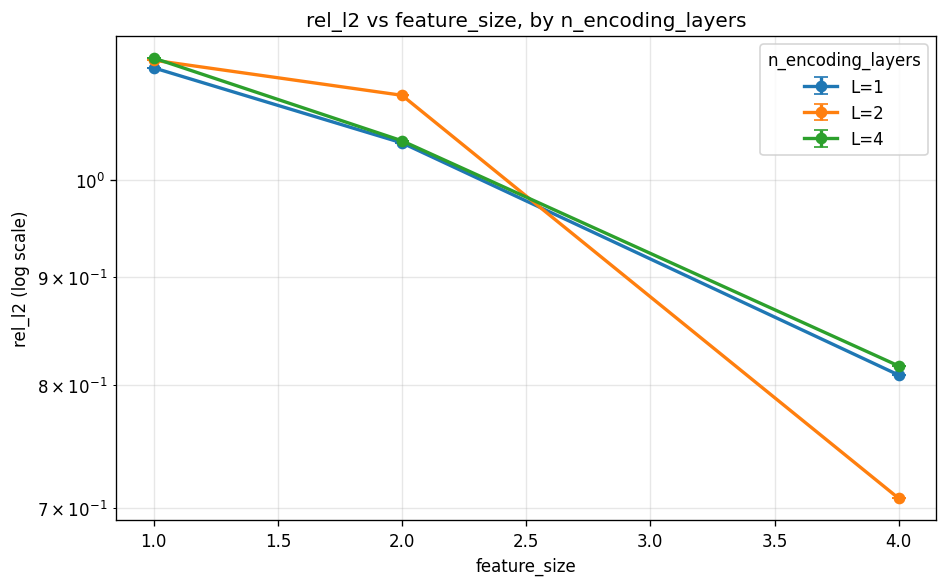

In [15]:
plot_rel_l2_vs_feature_size(results, feature_size_list, layers_list)

Parameters — total: 177  trainable: 177

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 6.8592e+00 | PDE: 9.66e-01 | Cons: 1.96e-01 | IC: 5.87e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/600 | Loss: 4.7798e+00 | PDE: 2.38e-01 | Cons: 2.22e-02 | IC: 4.54e-01 | BC: 0.00e+00 | Time: 2.4s
Epoch   100/600 | Loss: 1.7286e+00 | PDE: 6.51e-01 | Cons: 5.57e-01 | IC: 1.02e-01 | BC: 0.00e+00 | Time: 4.8s
Epoch   150/600 | Loss: 8.8441e-01 | PDE: 4.27e-01 | Cons: 1.15e+00 | IC: 3.42e-02 | BC: 0.00e+00 | Time: 7.1s
Epoch   200/600 | Loss: 4.8479e-01 | PDE: 1.62e-01 | Cons: 1.96e+00 | IC: 1.26e-02 | BC: 0.00e+00 | Time: 9.5s
Epoch   250/600 | Loss: 3.1487e-01 | PDE: 7.43e-02 | Cons: 2.00e+00 | IC: 4.06e-03 | BC: 0.00e+00 | Time: 11.8s
Epoch   300/600 | Loss: 2.7833e-01 | PDE: 2.86e-02 | Cons: 2.31e+00 | IC: 1.91e-03 | BC: 0.00e+00 | Time: 14.2s
Epoch   350/600 | Loss: 2.9291e-01 | PDE: 5.31e-02 | Cons: 2.20e+00 | IC: 2.02e-03 | BC: 0.00e+00 | Time: 16.5s
Epoch   400/60

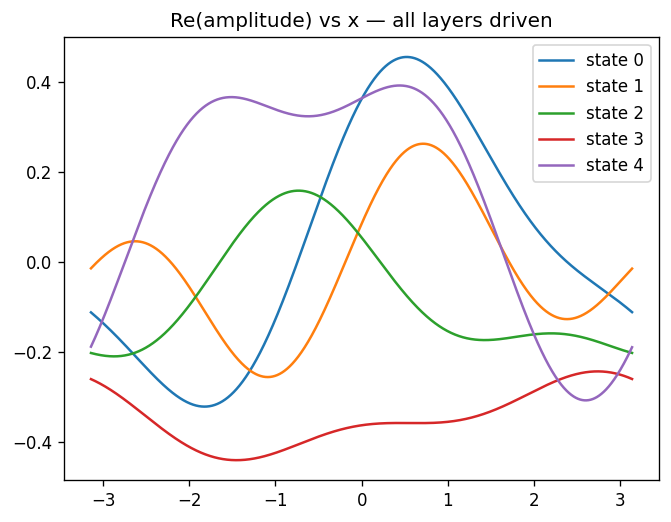

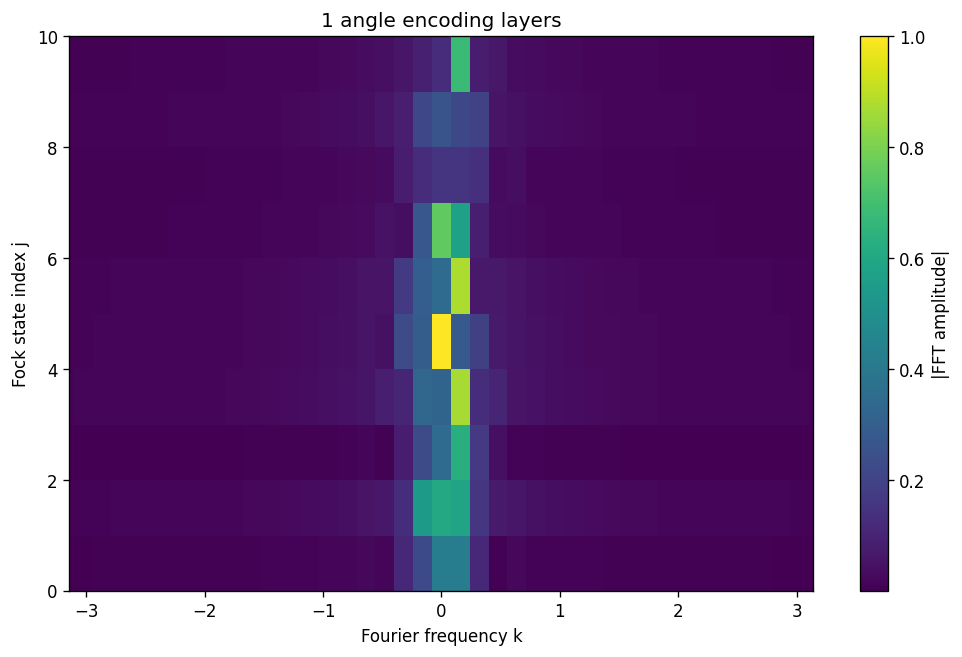

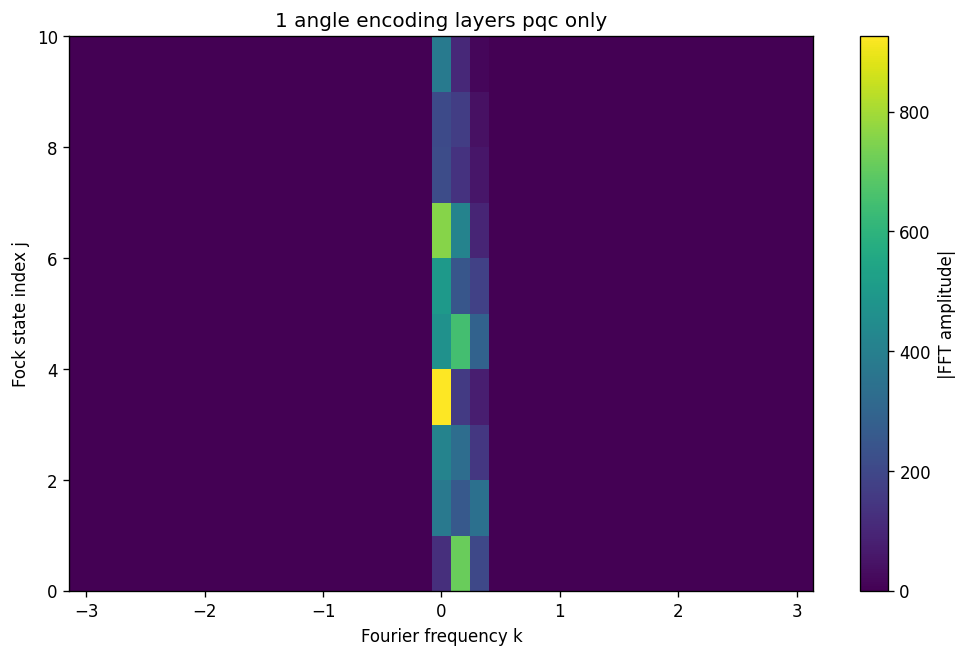

Parameters — total: 240  trainable: 240

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.6698e+00 | PDE: 1.32e+00 | Cons: 1.15e-01 | IC: 3.34e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/600 | Loss: 2.9555e+00 | PDE: 6.76e-01 | Cons: 2.51e-01 | IC: 2.25e-01 | BC: 0.00e+00 | Time: 3.7s
Epoch   100/600 | Loss: 1.2675e+00 | PDE: 5.38e-01 | Cons: 8.11e-01 | IC: 6.48e-02 | BC: 0.00e+00 | Time: 7.3s
Epoch   150/600 | Loss: 4.2432e-01 | PDE: 1.43e-01 | Cons: 1.75e+00 | IC: 1.06e-02 | BC: 0.00e+00 | Time: 10.9s
Epoch   200/600 | Loss: 3.2023e-01 | PDE: 4.39e-02 | Cons: 2.42e+00 | IC: 3.39e-03 | BC: 0.00e+00 | Time: 14.5s
Epoch   250/600 | Loss: 2.5938e-01 | PDE: 3.33e-02 | Cons: 2.03e+00 | IC: 2.32e-03 | BC: 0.00e+00 | Time: 18.2s
Epoch   300/600 | Loss: 2.8318e-01 | PDE: 2.55e-02 | Cons: 2.27e+00 | IC: 3.09e-03 | BC: 0.00e+00 | Time: 22.1s
Epoch   350/600 | Loss: 2.4980e-01 | PDE: 2.27e-02 | Cons: 2.12e+00 | IC: 1.56e-03 | BC: 0.00e+00 | Time: 25.5s
Epoch   400/

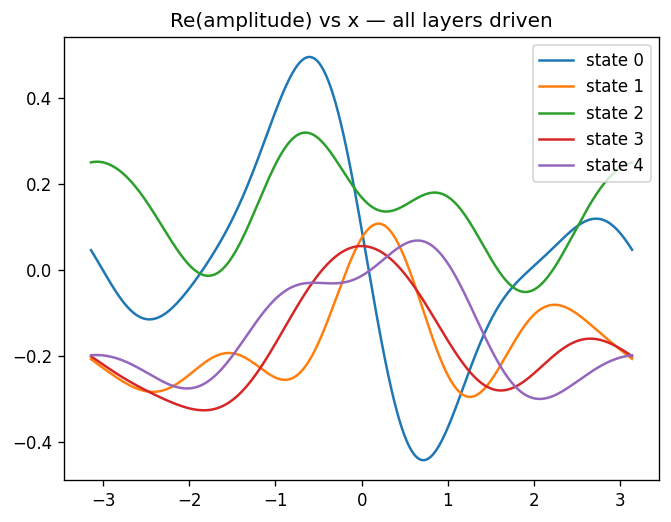

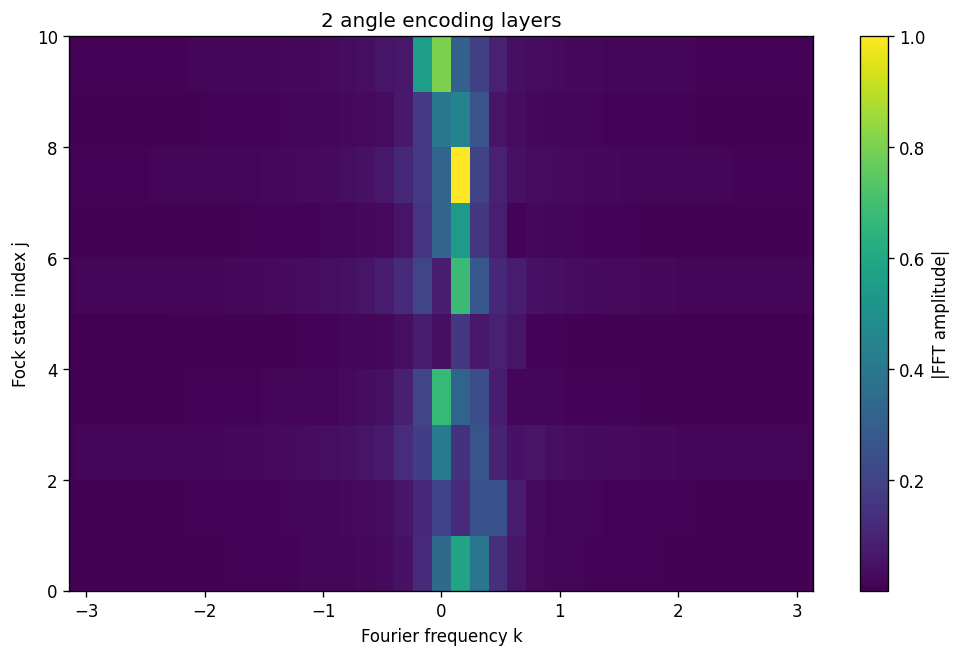

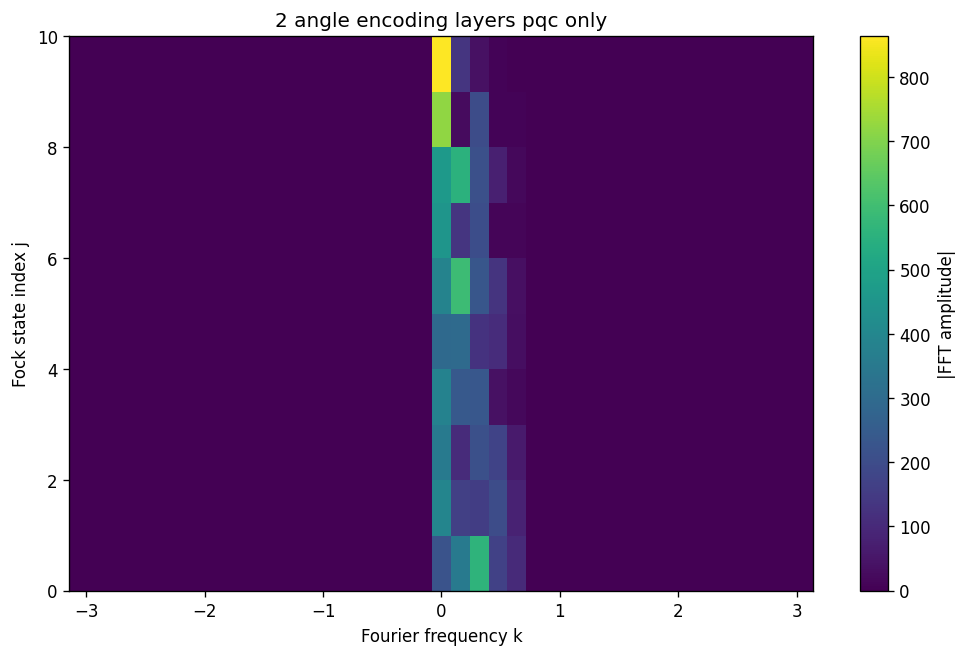

Parameters — total: 303  trainable: 303

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.3541e+00 | PDE: 5.86e-01 | Cons: 5.14e-02 | IC: 3.76e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/600 | Loss: 2.3090e+00 | PDE: 4.10e-01 | Cons: 3.21e-01 | IC: 1.87e-01 | BC: 0.00e+00 | Time: 4.7s
Epoch   100/600 | Loss: 5.3034e-01 | PDE: 1.91e-01 | Cons: 1.34e+00 | IC: 2.06e-02 | BC: 0.00e+00 | Time: 9.4s
Epoch   150/600 | Loss: 3.1572e-01 | PDE: 7.48e-02 | Cons: 1.97e+00 | IC: 4.40e-03 | BC: 0.00e+00 | Time: 14.1s
Epoch   200/600 | Loss: 3.1341e-01 | PDE: 2.54e-02 | Cons: 2.50e+00 | IC: 3.84e-03 | BC: 0.00e+00 | Time: 18.7s
Epoch   250/600 | Loss: 2.4356e-01 | PDE: 1.72e-02 | Cons: 2.10e+00 | IC: 1.60e-03 | BC: 0.00e+00 | Time: 23.4s
Epoch   300/600 | Loss: 2.6702e-01 | PDE: 1.83e-02 | Cons: 2.36e+00 | IC: 1.32e-03 | BC: 0.00e+00 | Time: 28.0s
Epoch   350/600 | Loss: 2.4991e-01 | PDE: 7.71e-03 | Cons: 2.21e+00 | IC: 2.07e-03 | BC: 0.00e+00 | Time: 32.6s
Epoch   400/

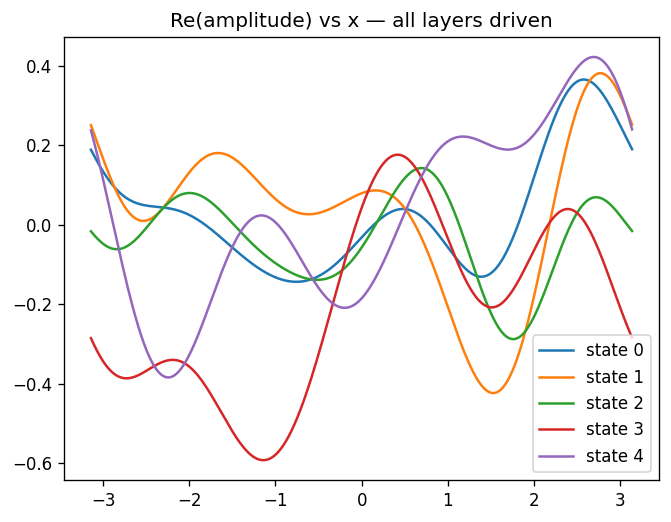

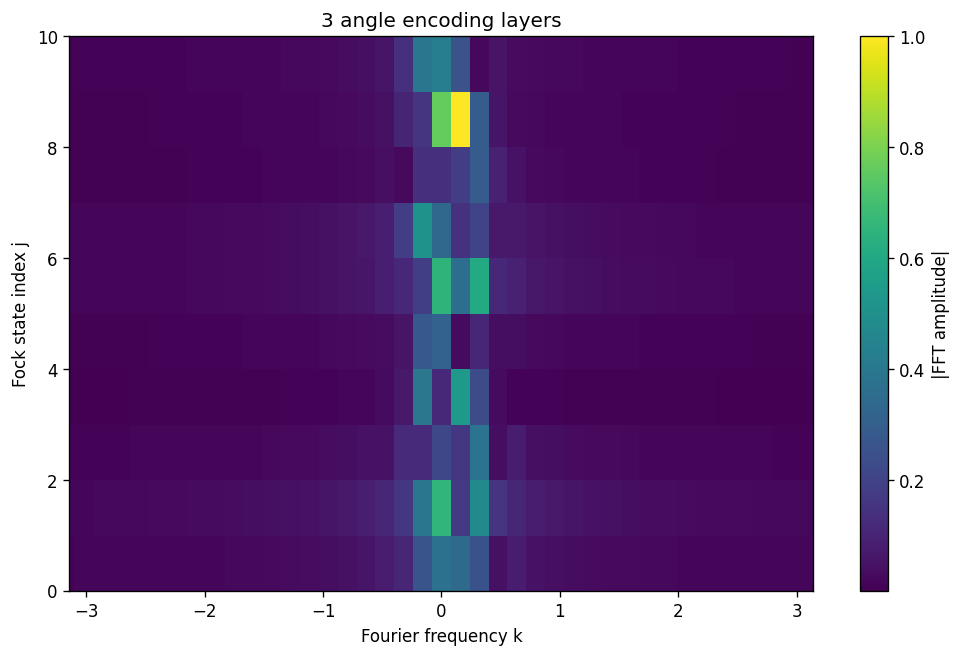

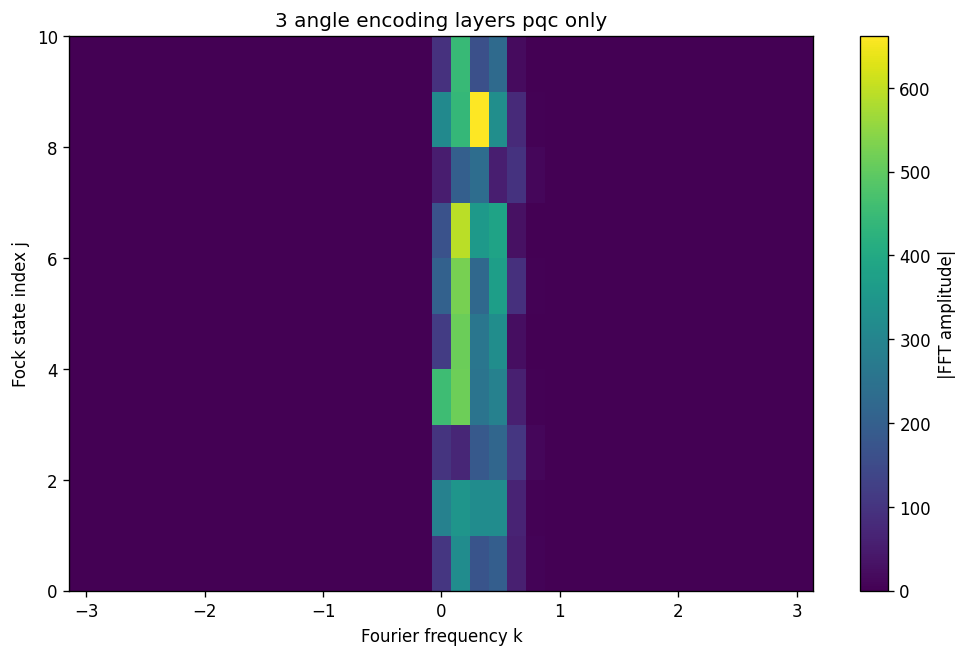

Parameters — total: 366  trainable: 366

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 4.8016e+00 | PDE: 2.14e-02 | Cons: 9.42e-03 | IC: 4.78e-01 | BC: 0.00e+00 | Time: 0.1s
Epoch    50/600 | Loss: 3.1262e+00 | PDE: 4.35e-01 | Cons: 1.80e-01 | IC: 2.67e-01 | BC: 0.00e+00 | Time: 6.3s
Epoch   100/600 | Loss: 1.2874e+00 | PDE: 4.95e-01 | Cons: 8.37e-01 | IC: 7.09e-02 | BC: 0.00e+00 | Time: 12.5s
Epoch   150/600 | Loss: 9.0603e-01 | PDE: 4.21e-01 | Cons: 1.16e+00 | IC: 3.69e-02 | BC: 0.00e+00 | Time: 18.8s
Epoch   200/600 | Loss: 5.3830e-01 | PDE: 1.33e-01 | Cons: 1.75e+00 | IC: 2.31e-02 | BC: 0.00e+00 | Time: 24.9s
Epoch   250/600 | Loss: 3.7155e-01 | PDE: 9.36e-02 | Cons: 1.87e+00 | IC: 9.11e-03 | BC: 0.00e+00 | Time: 31.0s
Epoch   300/600 | Loss: 3.2887e-01 | PDE: 7.52e-02 | Cons: 2.20e+00 | IC: 3.35e-03 | BC: 0.00e+00 | Time: 37.1s
Epoch   350/600 | Loss: 2.8271e-01 | PDE: 3.56e-02 | Cons: 2.09e+00 | IC: 3.77e-03 | BC: 0.00e+00 | Time: 43.2s
Epoch   400

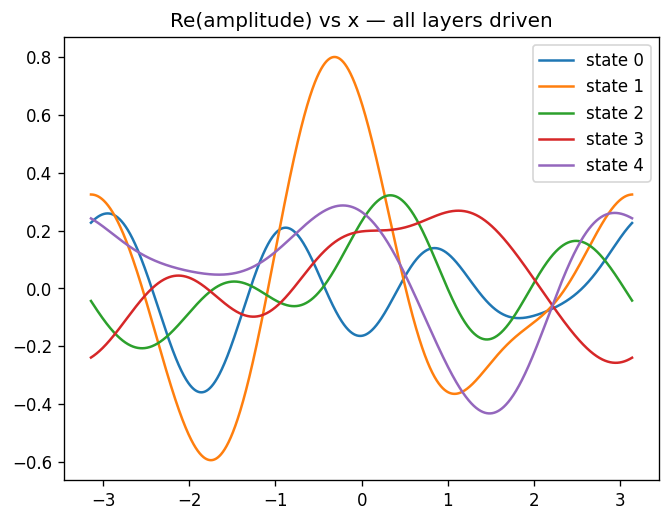

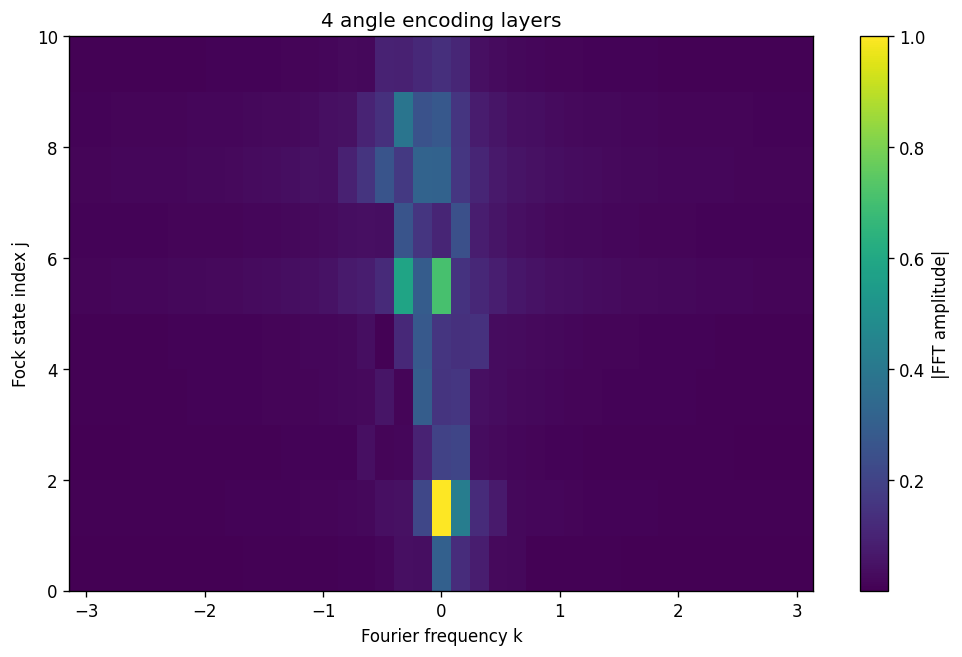

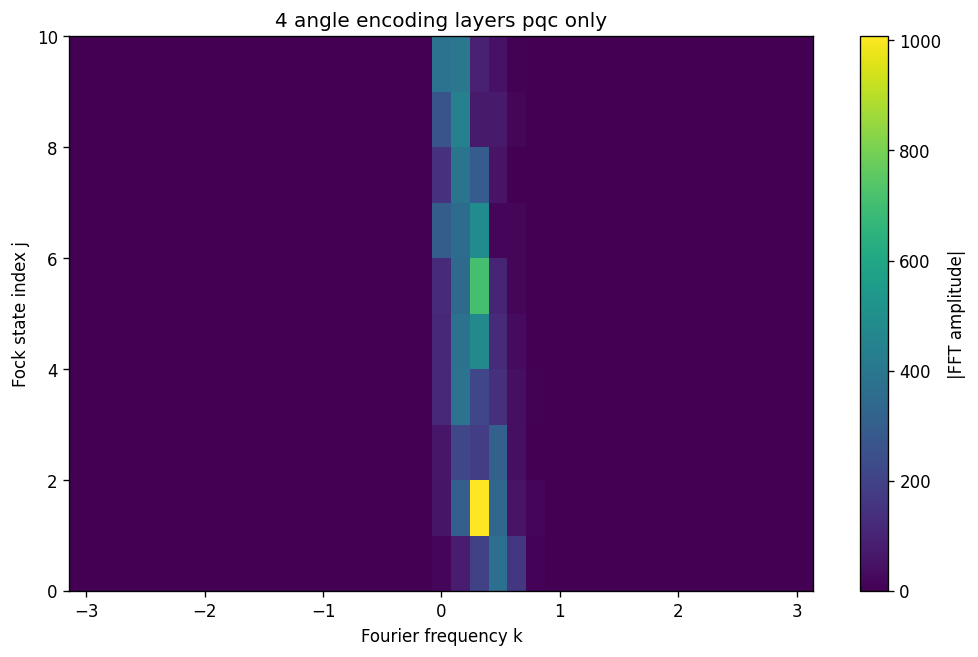

In [ ]:
layers = [1,2,3,4]

results = {}
history_qpinn_weights = []
trained_models = []
for L in layers:

    model = MerlinTunableEntropy(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=ref_pde, n_encoding_layers=L).to(device)
    history_qpinn_weights.append(train(model=model, pde=ref_pde, epochs = 600))
    trained_models.append(model)
    #model = qpinn_weights_ref

    print("PHASE SHIFTER CROSS CHECK")
    for i in range(model.feature_size):
        z = torch.zeros(
        (1, model.feature_size * model.n_encoding_layers),
        device=device
        )
        z[0,i]=1.0
        q1=model.quantum(z)

        z[0,i]=2.0
        q2=model.quantum(z)

        print(i, torch.norm(q1-q2))

    freqs, spectrum = compute_quantum_spectrum(model)
    freqs_pqc, spectrum_pqc = compute_pqc_only_spectrum(model)

    results[L] = (freqs, spectrum)

    plot_spectrum(
        freqs,
        spectrum,
        title=f"{L} angle encoding layers"
    )
    plot_spectrum(
        freqs_pqc,
        spectrum_pqc,
        title=f"{L} angle encoding layers pqc only"
    )

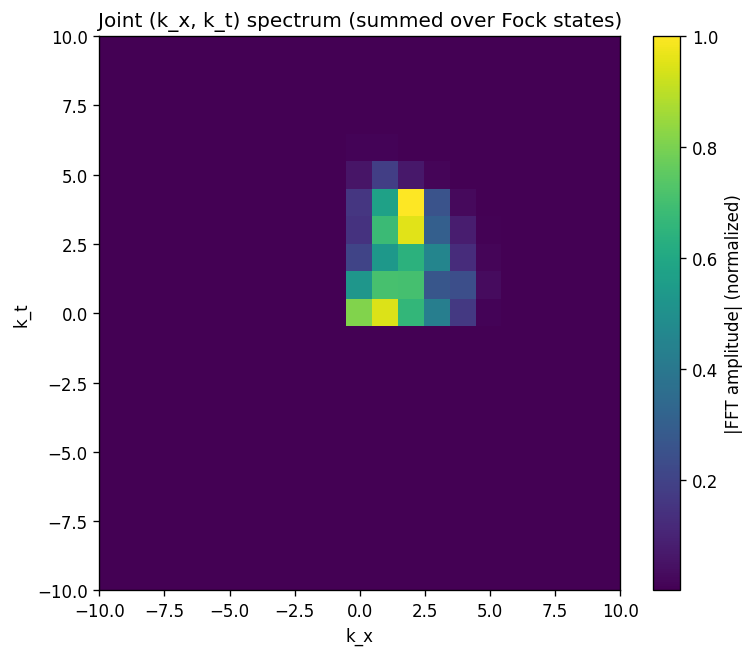

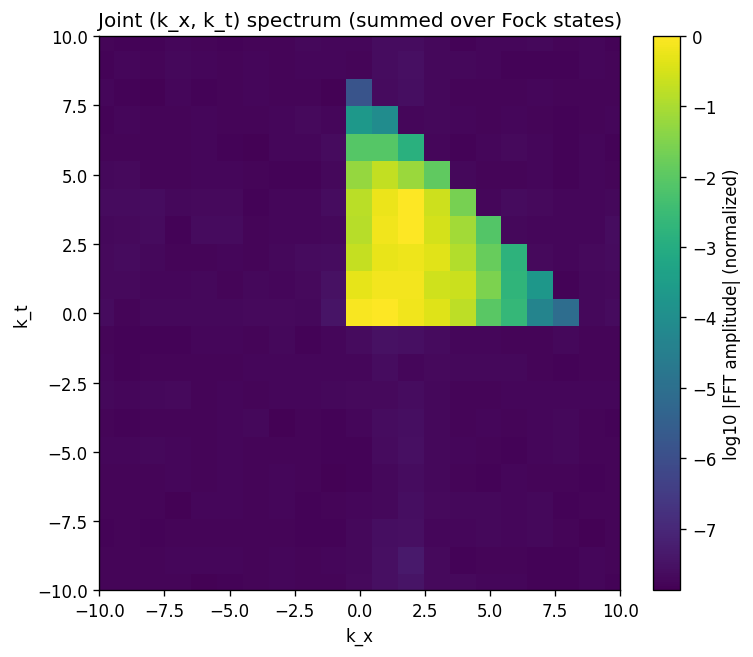

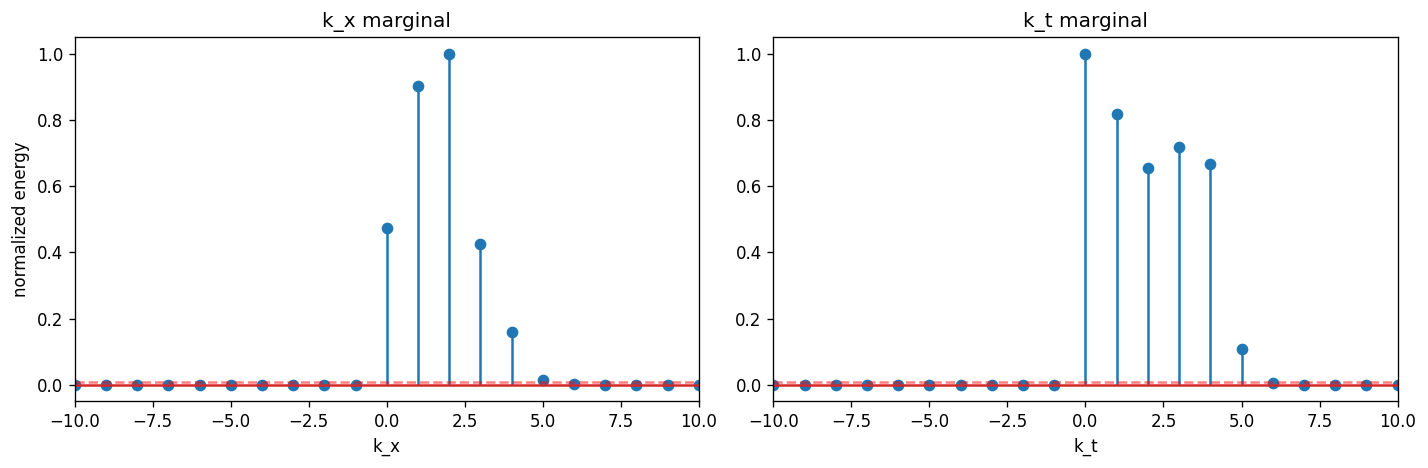

Effective bandwidth: k_x=5.00, k_t=5.00


In [22]:
def plot_spectrum_2d(kx, kt, spectrum_2d, fock_state=None,
                      title="Joint (k_x, k_t) spectrum", log_scale=False):
    """
    Plot the joint x-t frequency spectrum.

    Args:
        kx, kt:       1D frequency axes (from compute_pqc_only_spectrum_2d)
        spectrum_2d:  array, shape (n_kt, n_kx, n_fock_states), |FFT amplitude|
        fock_state:   if None, aggregate (sum) over all Fock states;
                       if an int, show that single Fock state's spectrum only
        log_scale:    use log color scale (helpful since energy often spans
                       orders of magnitude across k)
    """
    if fock_state is None:
        img = spectrum_2d.sum(axis=-1)
        subtitle = "(summed over Fock states)"
    else:
        img = spectrum_2d[..., fock_state]
        subtitle = f"(Fock state {fock_state})"

    img = img / img.max()

    if log_scale:
        img = np.log10(img + 1e-8)
        cbar_label = "log10 |FFT amplitude| (normalized)"
    else:
        cbar_label = "|FFT amplitude| (normalized)"

    plt.figure(figsize=(7, 6))
    plt.imshow(
        img,
        aspect="auto",
        extent=[kx[0], kx[-1], kt[0], kt[-1]],
        origin="lower",
        cmap="viridis",
    )
    plt.xlabel("k_x")
    plt.ylabel("k_t")
    plt.xlim([-10, 10])
    plt.ylim([-10, 10])
    plt.colorbar(label=cbar_label)
    plt.title(f"{title} {subtitle}")
    plt.show()


def plot_marginal_bandwidths(kx, kt, spectrum_2d, threshold=0.01):
    """
    Plot the k_x and k_t marginals (row/column sums of the aggregated
    spectrum) side by side -- this is the direct analogue of your 1D
    bandwidth measurement, but separated per axis.
    """
    img = spectrum_2d.sum(axis=-1)  # sum over Fock states -> (n_kt, n_kx)

    marginal_kx = img.sum(axis=0)   # sum over kt -> function of kx
    marginal_kt = img.sum(axis=1)   # sum over kx -> function of kt

    marginal_kx = marginal_kx / marginal_kx.max()
    marginal_kt = marginal_kt / marginal_kt.max()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].stem(kx, marginal_kx)
    axes[0].set_xlabel("k_x")
    axes[0].set_ylabel("normalized energy")
    axes[0].set_title("k_x marginal")
    axes[0].set_xlim([-10, 10])
    axes[0].axhline(threshold, color='r', linestyle='--', alpha=0.5)

    axes[1].stem(kt, marginal_kt)
    axes[1].set_xlabel("k_t")
    axes[1].set_title("k_t marginal")
    axes[1].set_xlim([-10, 10])
    axes[1].axhline(threshold, color='r', linestyle='--', alpha=0.5)

    fig.tight_layout()
    plt.show()

    active_kx = np.abs(kx[marginal_kx > threshold])
    active_kt = np.abs(kt[marginal_kt > threshold])
    bw_x = active_kx.max() if active_kx.size else 0.0
    bw_t = active_kt.max() if active_kt.size else 0.0
    print(f"Effective bandwidth: k_x={bw_x:.2f}, k_t={bw_t:.2f}")
    return bw_x, bw_t

kx, kt, spectrum_2d = compute_pqc_only_spectrum_2d(trained_models[3])

plot_spectrum_2d(kx, kt, spectrum_2d)                  # full 2D heatmap, log_scale=True often clearer
plot_spectrum_2d(kx, kt, spectrum_2d, log_scale=True)
bw_x, bw_t = plot_marginal_bandwidths(kx, kt, spectrum_2d)

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
Entropy range: 0.959718052566381 1.0247183519472172
Max possible (maximally mixed) S_max = log(min(dim_A, dim_B)): Ellipsis


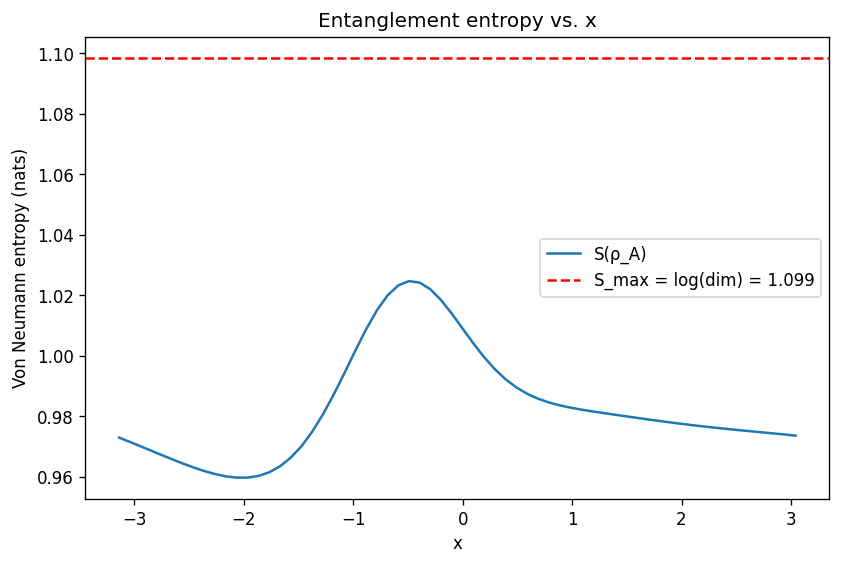

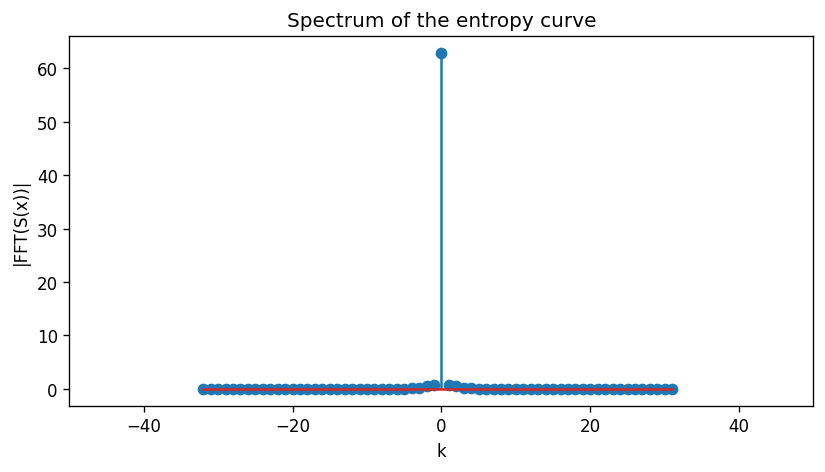

In [56]:
x_values, entropies, S_max = compute_entropy_curve(trained_models[1], n_points=64)
print("Entropy range:", entropies.min(), entropies.max())

print("Max possible (maximally mixed) S_max = log(min(dim_A, dim_B)):", ...)

plt.figure(figsize=(8, 5))
plt.plot(x_values, entropies, label="S(ρ_A)")
plt.axhline(S_max, color='r', linestyle='--', label=f"S_max = log(dim) = {S_max:.3f}")
plt.xlabel("x")
plt.ylabel("Von Neumann entropy (nats)")
plt.title("Entanglement entropy vs. x")
plt.legend()
plt.show()

S_fft = np.fft.fftshift(np.fft.fft(entropies))
freqs = np.fft.fftshift(np.fft.fftfreq(len(x_values), d=(x_values[1]-x_values[0])))
k_axis = freqs * 2 * np.pi

plt.figure(figsize=(8,4))
plt.stem(k_axis, np.abs(S_fft))
plt.xlim([-50, 50])
plt.xlabel("k")
plt.ylabel("|FFT(S(x))|")
plt.title("Spectrum of the entropy curve")
plt.show()

In [12]:
def compute_entropy_heatmap(model, n_points=128,
                             x_range=(-np.pi, np.pi),
                             t_range=(-np.pi, np.pi)):
    device = next(model.parameters()).device

    basis = get_basis_from_model(model)
    n_modes = len(basis[0])
    modes_A = list(range(model.feature_size))
    modes_B = [m for m in range(n_modes) if m not in modes_A]

    A_configs, B_configs = set(), set()
    for state in basis:
        A_configs.add(tuple(state[m] for m in modes_A))
        B_configs.add(tuple(state[m] for m in modes_B))
    dim_A, dim_B = len(A_configs), len(B_configs)
    S_max = np.log(min(dim_A, dim_B))
    print(f"n_modes={n_modes}, n_photons={model.quantum.n_photons}, "
          f"dim_A={dim_A}, dim_B={dim_B}, S_max={S_max:.4f} nats")

    x_values = np.linspace(x_range[0], x_range[1], n_points, endpoint=False)
    t_values = np.linspace(t_range[0], t_range[1], n_points, endpoint=False)

    S_grid = np.zeros((n_points, n_points))  # rows: t, cols: x

    model.eval()
    with torch.no_grad():
        for it, t in enumerate(t_values):
            for ix, x in enumerate(x_values):
                xt = torch.zeros((1, 2), device=device)
                xt[0, 0] = x
                xt[0, 1] = t
                z = model.feature_map(xt)
                q_amp = model.quantum(z).squeeze(0).cpu().numpy()
                S_grid[it, ix] = von_neumann_entropy_from_amplitudes(
                    q_amp, basis, modes_A
                )

    return x_values, t_values, S_grid, S_max


def plot_entropy_heatmap(x_values, t_values, S_grid, S_max):
    plt.figure(figsize=(8, 6))
    plt.imshow(
        S_grid,
        aspect="auto",
        extent=[x_values[0], x_values[-1], t_values[0], t_values[-1]],
        origin="lower",
        vmin=0,
        vmax=S_max,
    )
    plt.xlabel("x")
    plt.ylabel("t")
    plt.title("Von Neumann entropy S(x,t)")
    plt.colorbar(label="S (nats)")
    plt.show()

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats


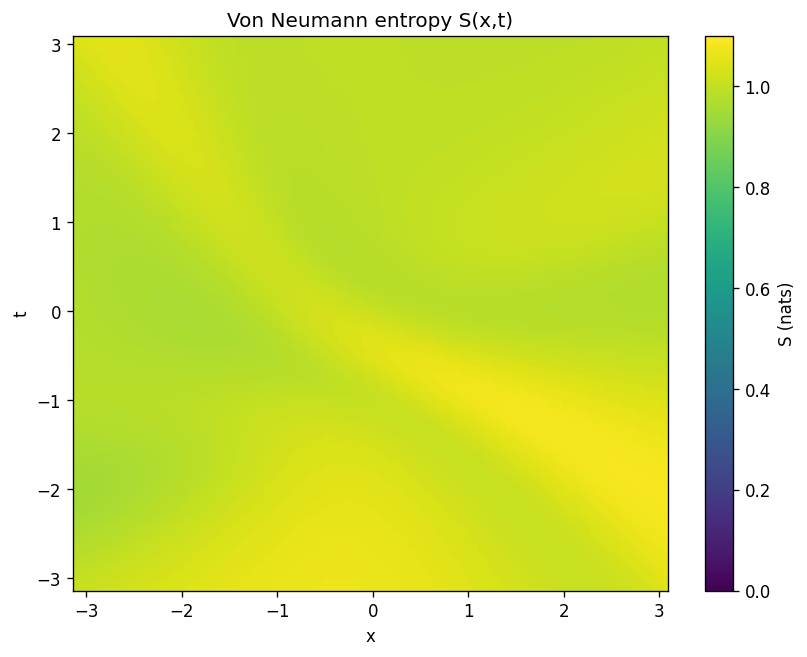

In [57]:
x_values, t_values, S_grid, S_max = compute_entropy_heatmap(trained_models[1])
plot_entropy_heatmap(x_values, t_values, S_grid, S_max)

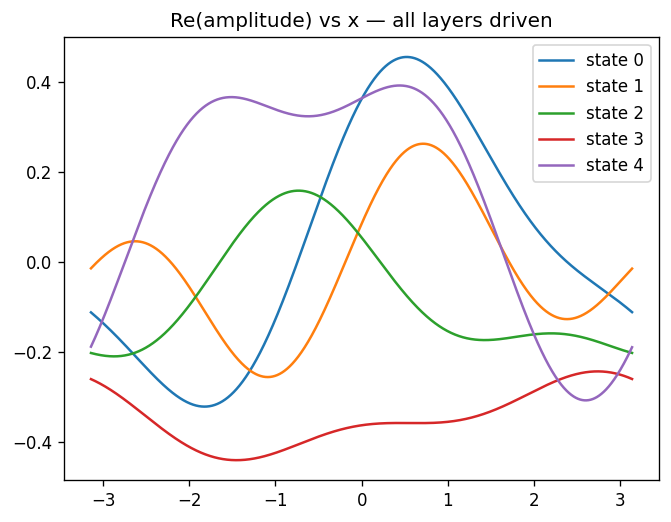

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats


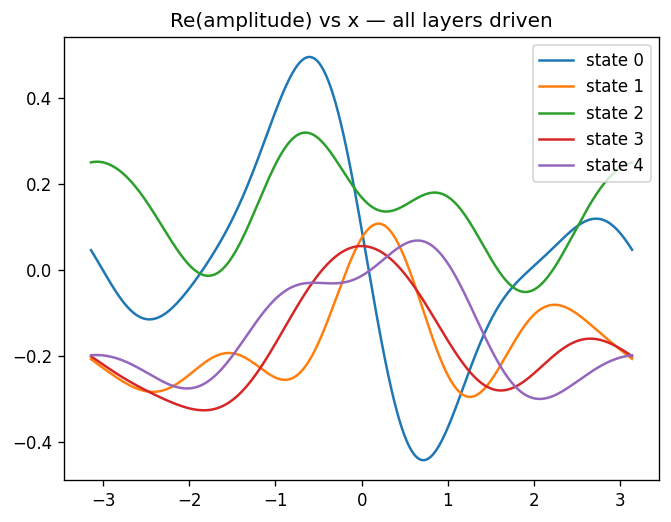

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats


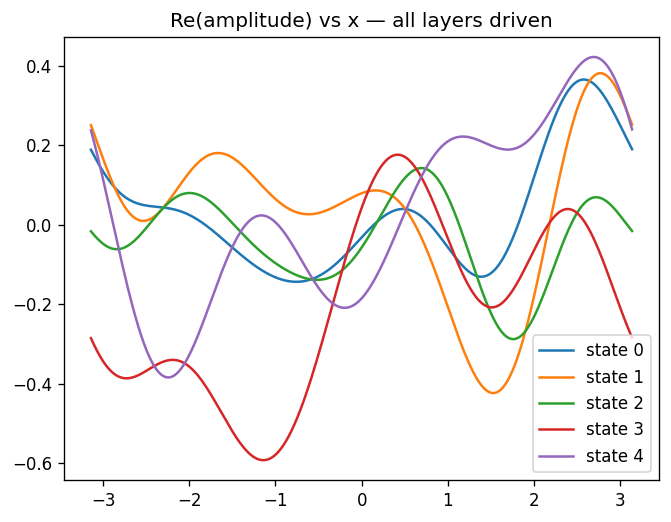

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats


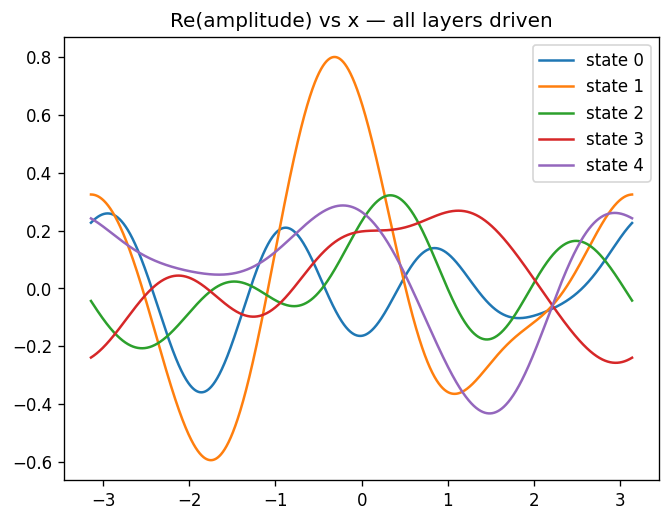

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
0: bandwidth=2.00, mean_entropy=0.832
1: bandwidth=4.00, mean_entropy=0.983
2: bandwidth=4.00, mean_entropy=0.764
3: bandwidth=4.00, mean_entropy=0.492


In [23]:
results = []
for i in range(len(trained_models)):
    variant_name = i
    variant_model = trained_models[i]
    freqs, spectrum = compute_pqc_only_spectrum(variant_model)
    # crude effective bandwidth: max |k| with energy above threshold
    k_axis = freqs * 2 * np.pi
    energy_per_k = spectrum.sum(axis=0)  # sum over Fock states
    energy_per_k /= energy_per_k.max()
    active_k = np.abs(k_axis[energy_per_k > 0.05])
    bandwidth = active_k.max() if len(active_k) else 0

    x_vals, entropies, S_max = compute_entropy_curve(variant_model)
    mean_entropy = entropies.mean()

    results.append((variant_name, bandwidth, mean_entropy))

for name, bw, ent in results:
    print(f"{name}: bandwidth={bw:.2f}, mean_entropy={ent:.3f}")

In [81]:
# Try to find Perceval's own state enumeration utility
import perceval as pcvl

# Option A: Perceval usually exposes a canonical enumerator for all
# Fock states reachable from a given input BasicState under mode-preserving
# (photon-number-conserving) evolution:
try:
    from perceval.utils import BasicState
    input_bs = pcvl.BasicState([1,0,1,0,1])  # match your input_state
    states = list(input_bs.separate_state())  # or similar - check actual method
    print(states[:10])
except Exception as e:
    print("Option A failed:", e)

# Option B: inspect the QuantumLayer / builder object directly
print([a for a in dir(model.quantum) if not a.startswith('_')])
# Look for anything like: output_states, fock_states, basis, hilbert_space,
# computation_space, measurement_strategy internals, etc.

# Option C: inspect the measurement strategy object itself
print(model.quantum.measurement_strategy)
print([a for a in dir(model.quantum.measurement_strategy) if not a.startswith('_')])

Option A failed: 'exqalibur.FockState' object has no attribute 'separate_state'
['LI_simple', 'MI_simple', 'RI_simple', 'T_destination', 'add_module', 'amplitude_encoding', 'angle_encoding_specs', 'apply', 'as_simulation', 'bfloat16', 'buffers', 'call_super_init', 'children', 'circuit', 'compile', 'complex_dtype', 'computation_process', 'computation_space', 'cpu', 'cuda', 'detectors', 'device', 'double', 'dtype', 'dump_patches', 'eval', 'experiment', 'export_config', 'extra_repr', 'float', 'force_local', 'forward', 'get_buffer', 'get_extra_state', 'get_parameter', 'get_submodule', 'half', 'has_custom_detectors', 'has_custom_noise_model', 'input_parameters', 'input_size', 'input_state', 'ipu', 'load_state_dict', 'measurement_mapping', 'measurement_strategy', 'modules', 'mtia', 'n_photons', 'named_buffers', 'named_children', 'named_modules', 'named_parameters', 'noise_model', 'output_keys', 'output_size', 'parameters', 'prepare_parameters', 'register_backward_hook', 'register_buffer', 'r

In [79]:
print(model.quantum.output_keys)
print(type(model.quantum.output_keys))
print(len(model.quantum.output_keys))

[(2, 0, 0, 0), (1, 1, 0, 0), (1, 0, 1, 0), (1, 0, 0, 1), (0, 2, 0, 0), (0, 1, 1, 0), (0, 1, 0, 1), (0, 0, 2, 0), (0, 0, 1, 1), (0, 0, 0, 2)]
<class 'list'>
10


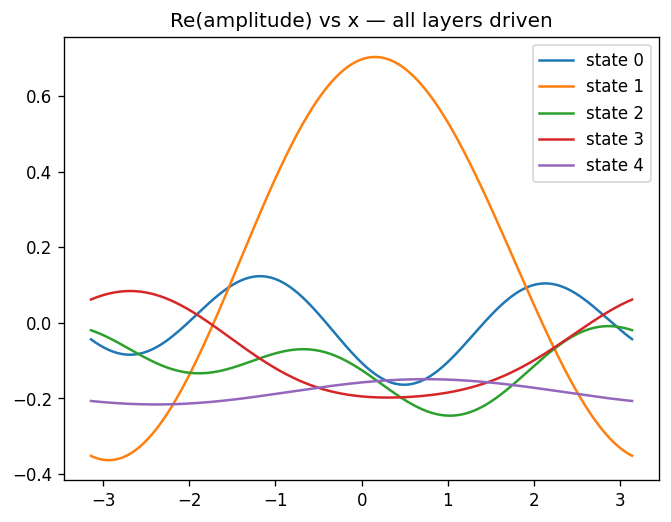

1 2.0


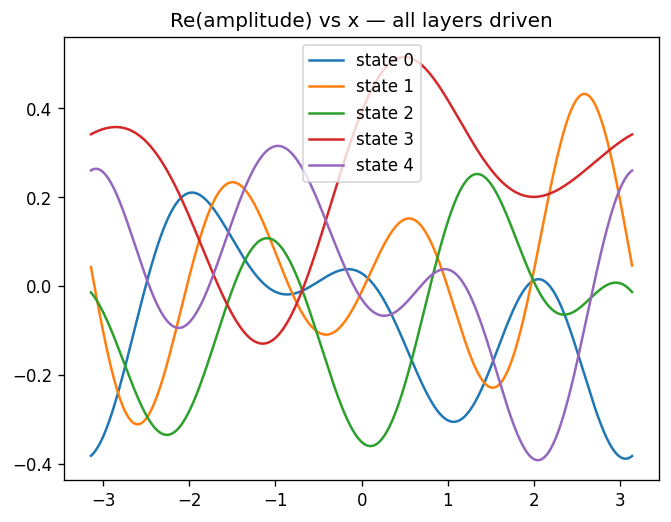

2 4.0


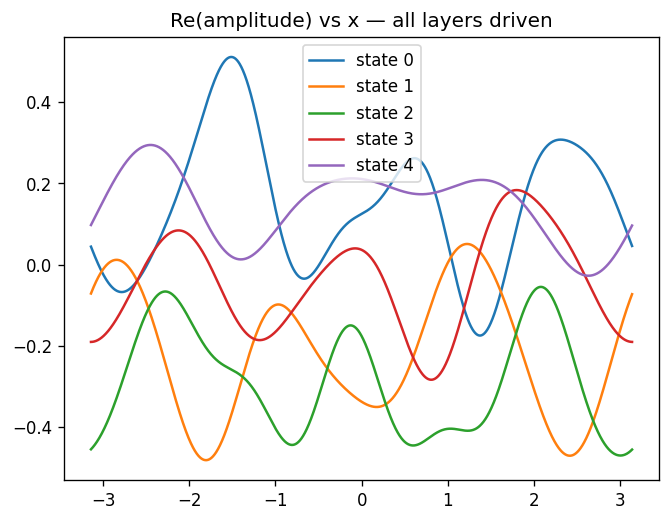

3 6.0


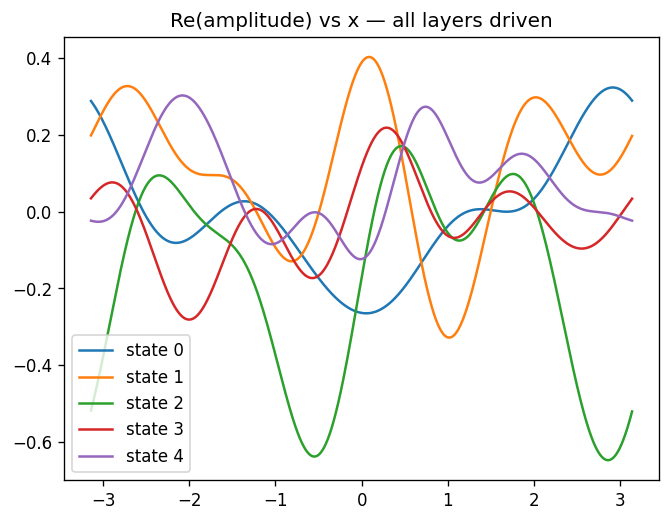

4 7.000000000000001


In [24]:
bandwidths = {}
for L in layers:
    model = MerlinTunableEntropy(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=ref_pde, n_encoding_layers=L).to(device)
    freqs, spectrum = compute_pqc_only_spectrum(model)  # the corrected version
    k_axis = freqs * 2*np.pi
    energy = spectrum.sum(axis=0); energy /= energy.max()
    active_k = np.abs(k_axis[energy > 0.01])
    bandwidths[L] = active_k.max() if len(active_k) else 0
    print(L, bandwidths[L])

Evaluating on 128×128 grid …
  Relative L2 : 2.2824e-02
  MAE         : 9.1446e-03
  Max abs err : 2.3833e-02
  RMSE        : 1.1412e-02


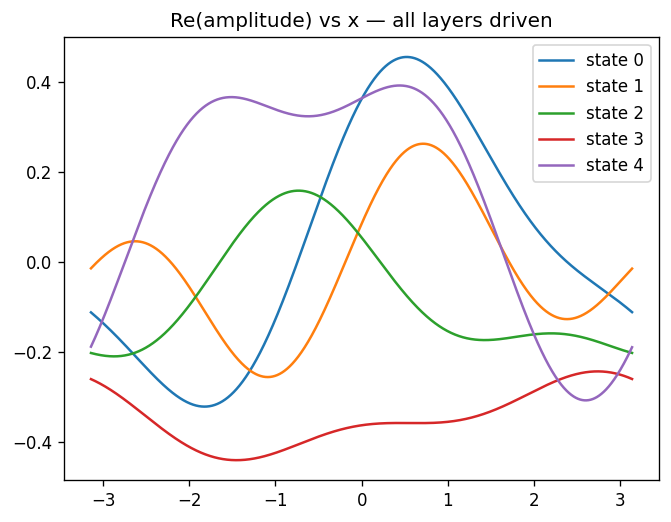

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
[{'L': 1, 'rel_l2': 0.022824138402938843, 'bandwidth': 2.0, 'mean_entropy': np.float64(0.8321616563834121)}]
Evaluating on 128×128 grid …
  Relative L2 : 2.2824e-02
  MAE         : 9.1446e-03
  Max abs err : 2.3833e-02
  RMSE        : 1.1412e-02


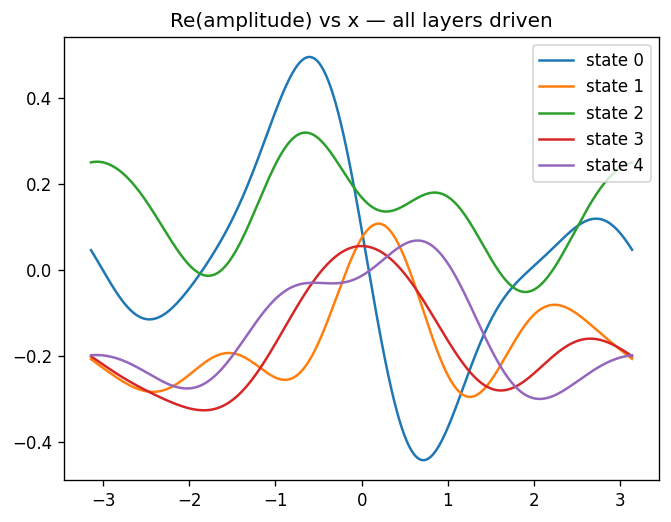

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
[{'L': 1, 'rel_l2': 0.022824138402938843, 'bandwidth': 2.0, 'mean_entropy': np.float64(0.8321616563834121)}, {'L': 2, 'rel_l2': 0.022824138402938843, 'bandwidth': 4.0, 'mean_entropy': np.float64(0.9833734950485662)}]
Evaluating on 128×128 grid …
  Relative L2 : 2.2824e-02
  MAE         : 9.1446e-03
  Max abs err : 2.3833e-02
  RMSE        : 1.1412e-02


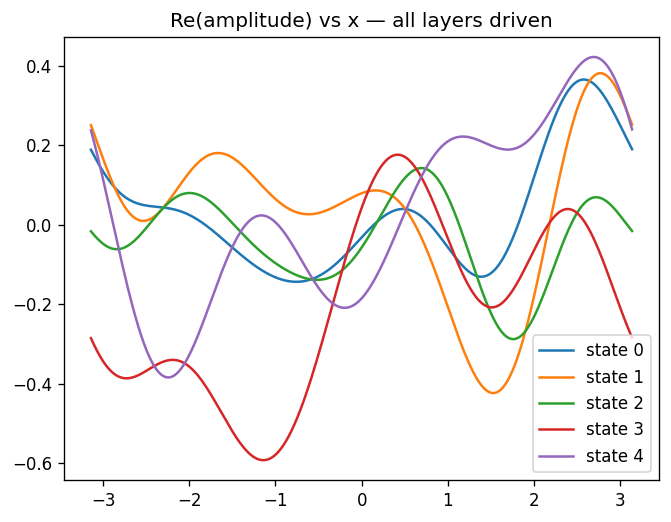

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
[{'L': 1, 'rel_l2': 0.022824138402938843, 'bandwidth': 2.0, 'mean_entropy': np.float64(0.8321616563834121)}, {'L': 2, 'rel_l2': 0.022824138402938843, 'bandwidth': 4.0, 'mean_entropy': np.float64(0.9833734950485662)}, {'L': 3, 'rel_l2': 0.022824138402938843, 'bandwidth': 5.0, 'mean_entropy': np.float64(0.76364456903217)}]
Evaluating on 128×128 grid …
  Relative L2 : 2.2824e-02
  MAE         : 9.1446e-03
  Max abs err : 2.3833e-02
  RMSE        : 1.1412e-02


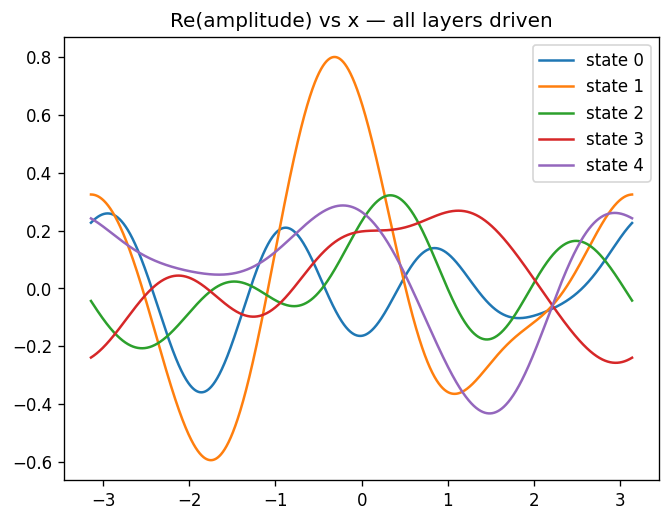

n_modes=4, n_photons=2, dim_A=10, dim_B=3, S_max=1.0986 nats
[{'L': 1, 'rel_l2': 0.022824138402938843, 'bandwidth': 2.0, 'mean_entropy': np.float64(0.8321616563834121)}, {'L': 2, 'rel_l2': 0.022824138402938843, 'bandwidth': 4.0, 'mean_entropy': np.float64(0.9833734950485662)}, {'L': 3, 'rel_l2': 0.022824138402938843, 'bandwidth': 5.0, 'mean_entropy': np.float64(0.76364456903217)}, {'L': 4, 'rel_l2': 0.022824138402938843, 'bandwidth': 5.0, 'mean_entropy': np.float64(0.4919859880401045)}]


In [25]:
def effective_bandwidth(freqs, spectrum, threshold=0.01):
    """
    Estimate the effective spectral bandwidth from a (freqs, spectrum) pair
    as returned by compute_pqc_only_spectrum_fixed / compute_quantum_spectrum.

    Args:
        freqs:     1D array, FFT frequencies in *cycle* units (as returned
                   by np.fft.fftfreq) -- will be rescaled to k = freqs * 2*pi.
        spectrum:  2D array, shape (n_fock_states, n_freqs), |FFT amplitude|
                   per Fock state per frequency (as returned by the spectrum
                   functions above).
        threshold: relative energy cutoff (fraction of peak) below which a
                   frequency bin is considered "inactive" / noise floor.

    Returns:
        bandwidth: max |k| among frequency bins whose aggregated energy
                   (summed across all Fock states) exceeds `threshold`
                   times the peak aggregated energy. Returns 0.0 if no
                   bin clears the threshold (degenerate/flat case).
    """
    k_axis = freqs * 2 * np.pi

    # aggregate energy across all Fock states at each frequency
    energy_per_k = np.sum(spectrum, axis=0)

    peak = energy_per_k.max()
    if peak <= 0:
        return 0.0
    energy_per_k = energy_per_k / peak

    active_k = np.abs(k_axis[energy_per_k > threshold])

    return float(active_k.max()) if active_k.size > 0 else 0.0

records = []
grid_n = 128
for L, model in zip(layers, trained_models):
    metrics, U_pred, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)
    freqs, spectrum = compute_pqc_only_spectrum(model)  # post-training bandwidth
    x_vals, entropies, S_max = compute_entropy_curve(model)
    records.append({
        "L": L,
        "rel_l2": metrics["rel_l2"],
        "bandwidth": effective_bandwidth(freqs, spectrum),
        "mean_entropy": entropies.mean(),
    })
    print(records)

Evaluating on 128×128 grid …
  Relative L2 : 4.9933e-02
  MAE         : 1.9958e-02
  Max abs err : 6.2447e-02
  RMSE        : 2.4966e-02


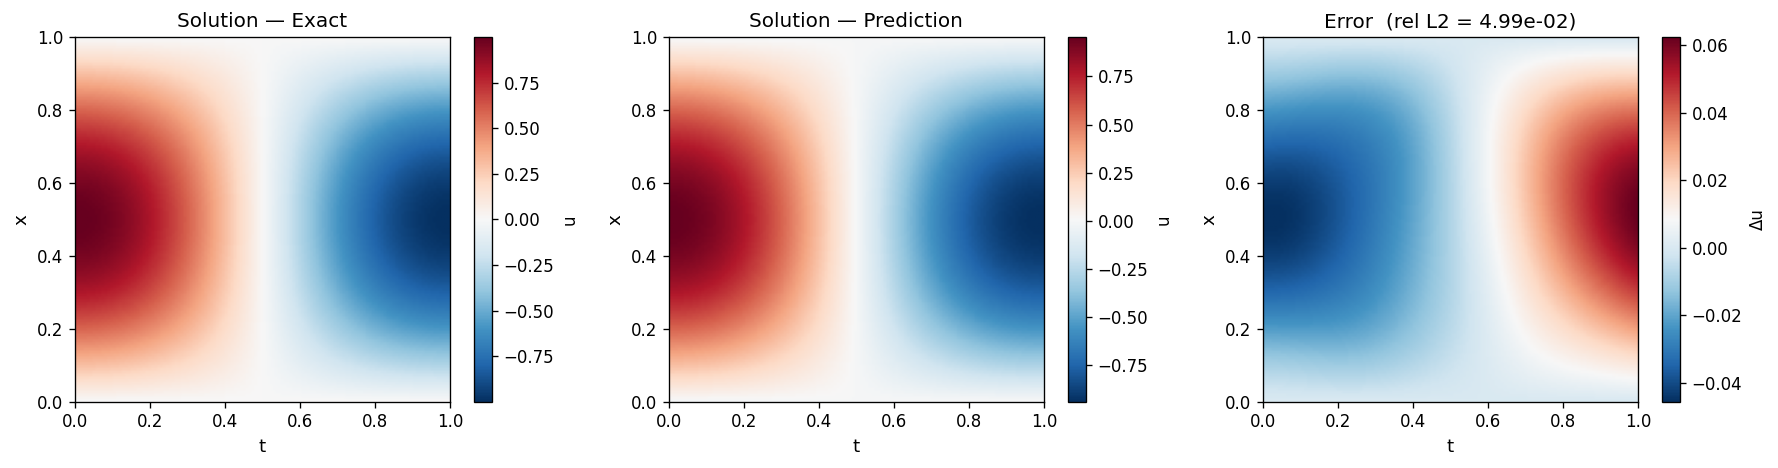

Evaluating on 128×128 grid …
  Relative L2 : 5.7379e-02
  MAE         : 2.3236e-02
  Max abs err : 6.2296e-02
  RMSE        : 2.8689e-02


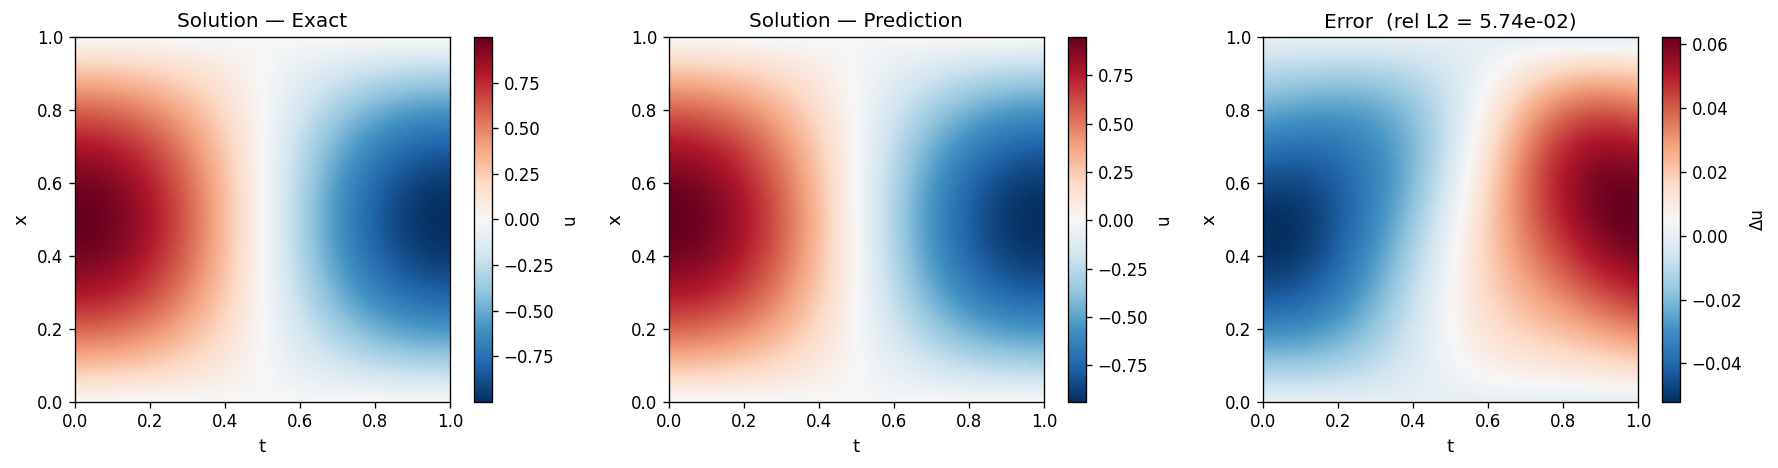

Evaluating on 128×128 grid …
  Relative L2 : 5.5691e-02
  MAE         : 2.2231e-02
  Max abs err : 6.6639e-02
  RMSE        : 2.7845e-02


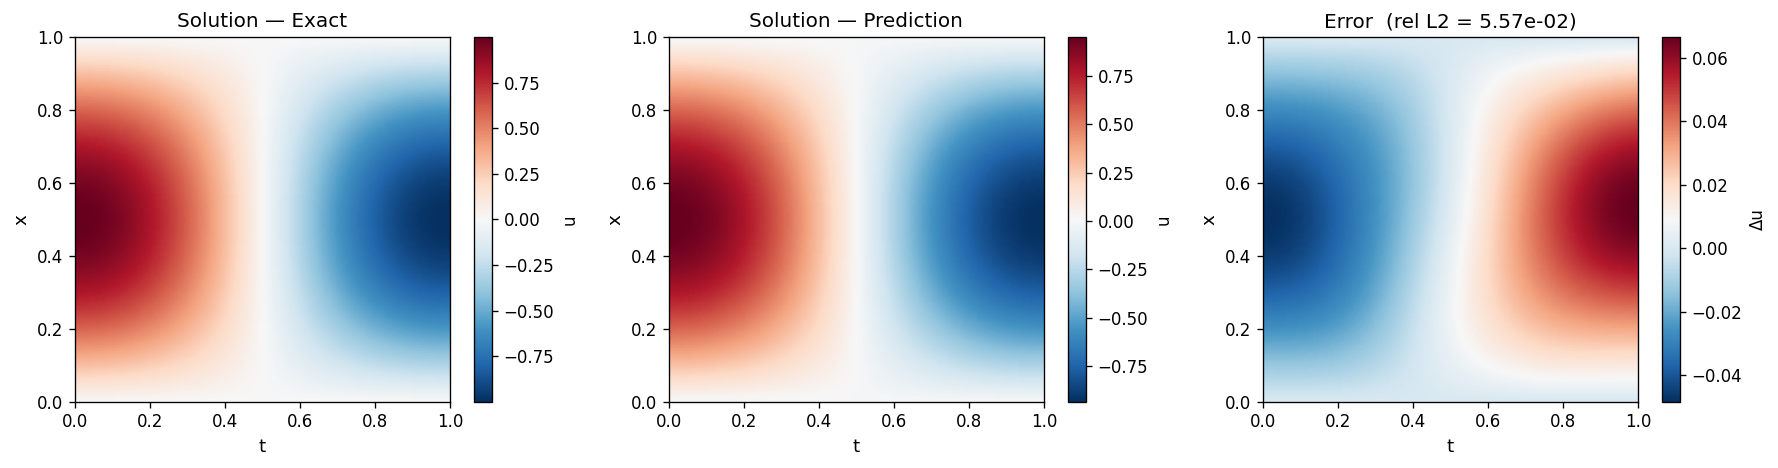

Evaluating on 128×128 grid …
  Relative L2 : 5.7465e-02
  MAE         : 2.3123e-02
  Max abs err : 6.6579e-02
  RMSE        : 2.8732e-02


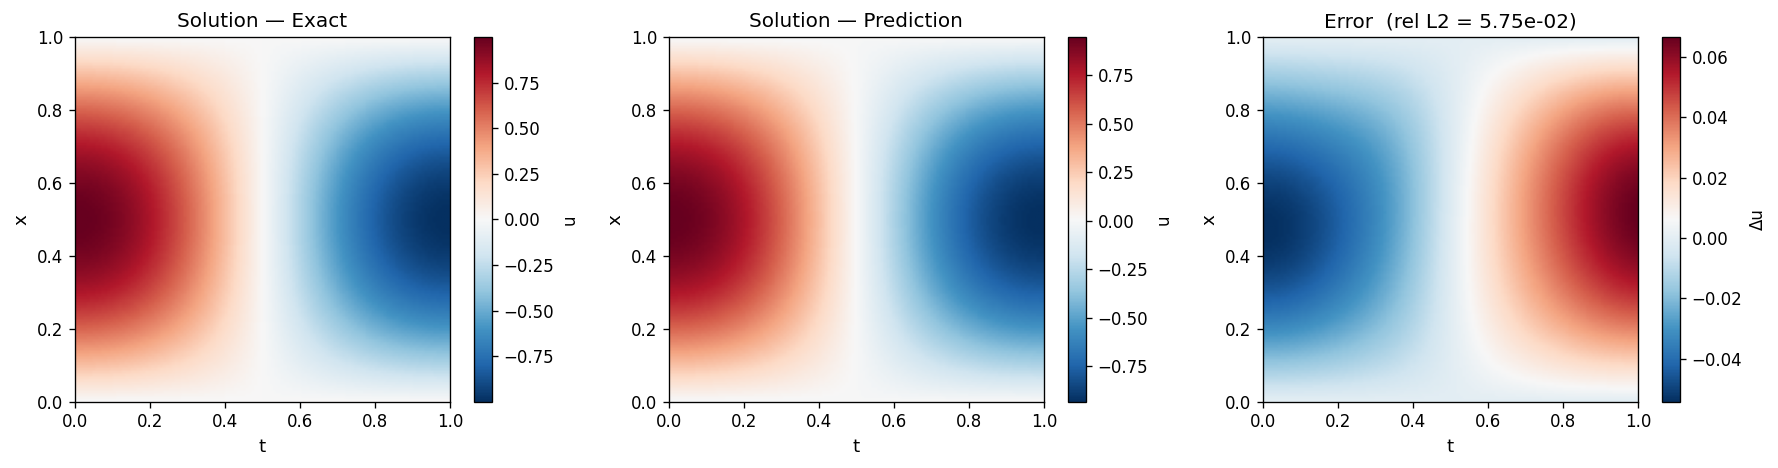

In [26]:
grid_n = 128
for model in trained_models:
    _, U_pred, U_true, x_grid, t_grid = evaluate(model=model, pde=ref_pde, device=device, dtype=dtype, nx=grid_n, nt=grid_n)
    plot_solution_comparison(U_pred,U_true, x_grid, t_grid)

In [47]:
print(model.pde is ref_pde)              # same object?
print(model.pde.freq, ref_pde.freq)      # same frequency parameter?
print(model.pde.x_min, ref_pde.x_min, model.pde.x_max, ref_pde.x_max)

# direct numerical check at t=0
x_check = torch.linspace(ref_pde.x_min, ref_pde.x_max, 200).reshape(-1,1)
t_check = torch.zeros_like(x_check)
xt_check = torch.cat([x_check, t_check], dim=1)
with torch.no_grad():
    u_pred_t0, _ = model(xt_check)
u_true_t0 = ref_pde.initial_condition(x_check)
print("max diff at t=0:", (u_pred_t0 - u_true_t0).abs().max().item())

True
2 2
0.0 0.0 1.0 1.0
max diff at t=0: 0.0


True


In [67]:
# Evaluate models
grid_n = 128
print(ref_pde.x_min, ref_pde.x_max, ref_pde.t_min, ref_pde.t_max, ref_pde.freq, )
print(ref_pde)

_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

0.0 1.0 0.0 1.0 2
WaveEquation(x_min=0.0, x_max=1.0, t_min=0.0, t_max=1.0, c=1.0, freq=2)
Evaluating on 128×128 grid …
  Relative L2 : 8.1671e-01
  MAE         : 3.0673e-01
  Max abs err : 1.0800e+00
  RMSE        : 4.0834e-01
Evaluating on 128×128 grid …
  Relative L2 : 9.4871e-01
  MAE         : 3.6378e-01
  Max abs err : 1.0833e+00
  RMSE        : 4.7434e-01
Evaluating on 128×128 grid …
  Relative L2 : 5.4716e-01
  MAE         : 2.0484e-01
  Max abs err : 7.1280e-01
  RMSE        : 2.7357e-01


#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

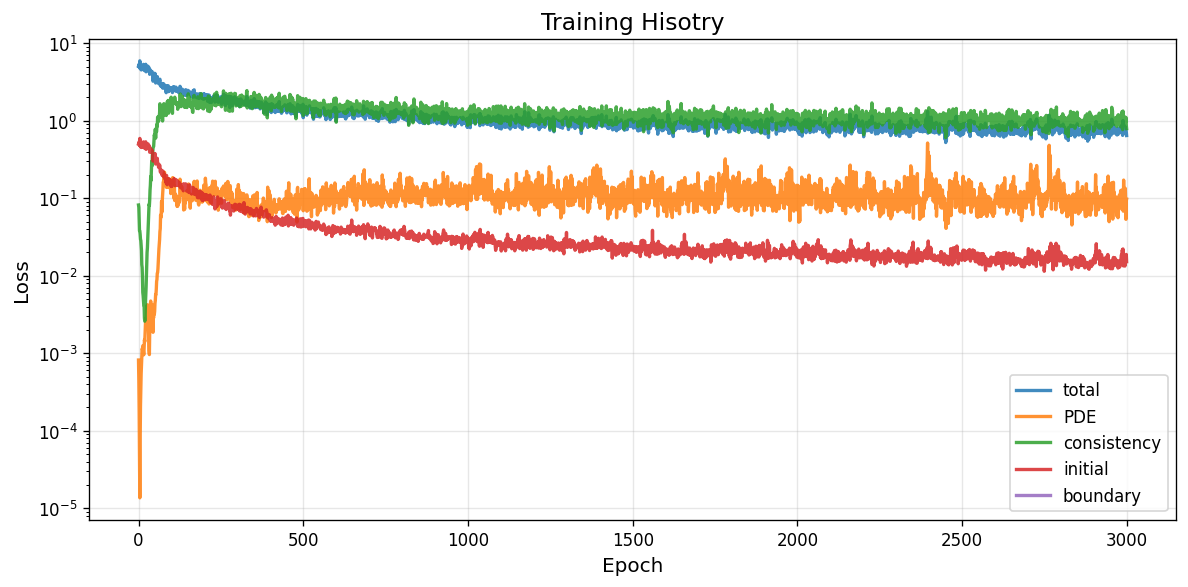

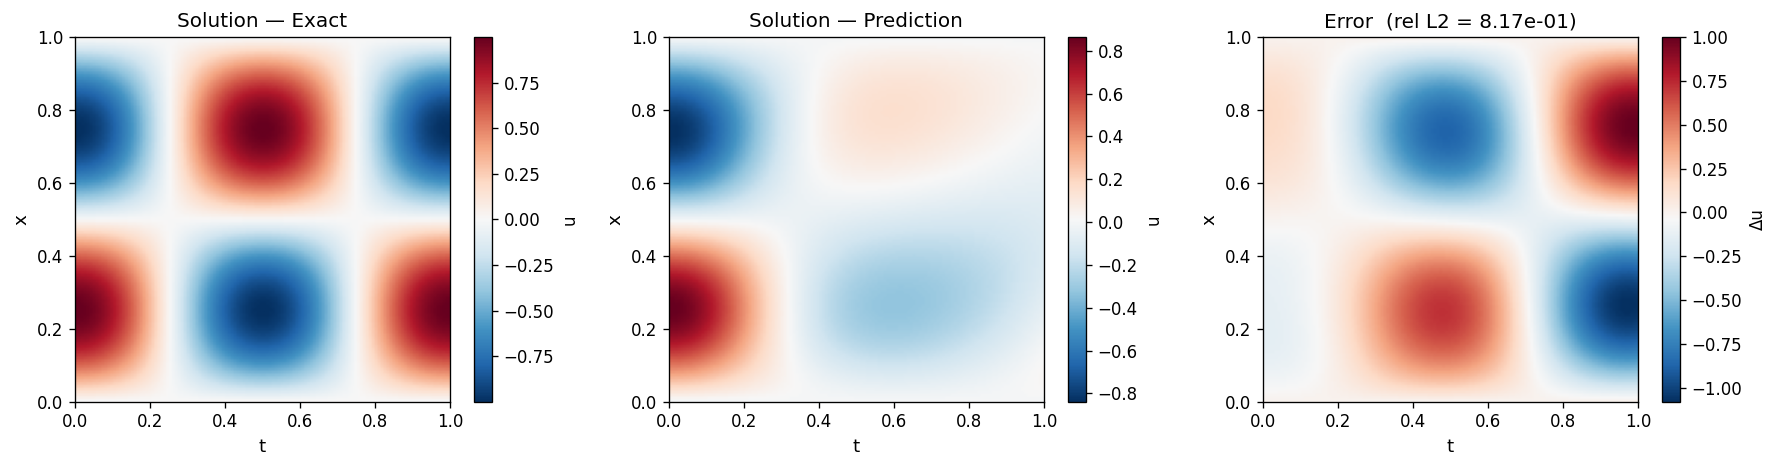

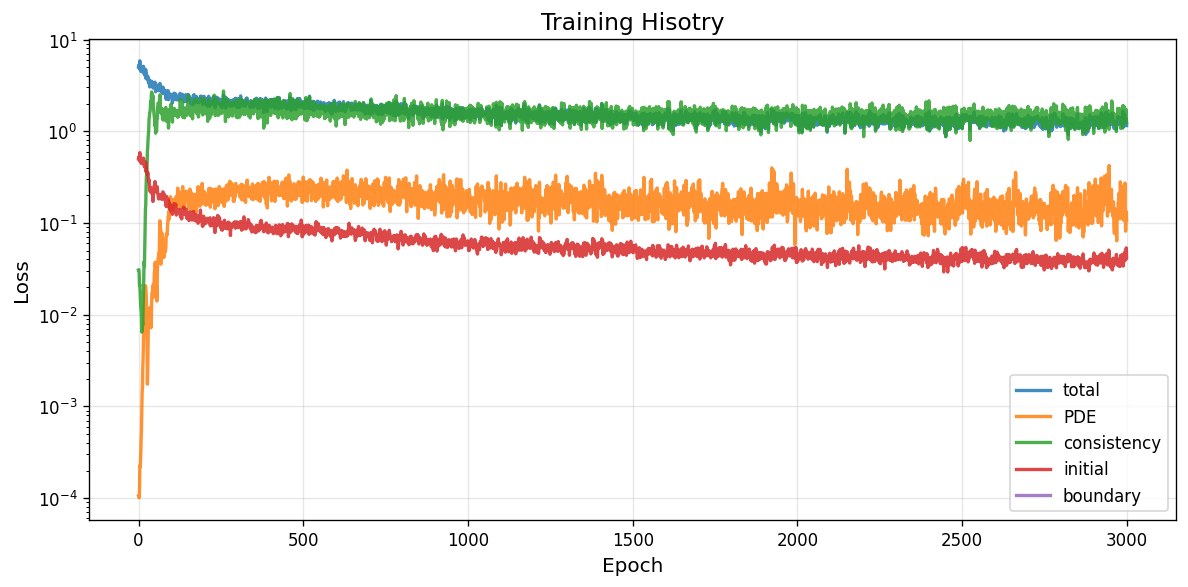

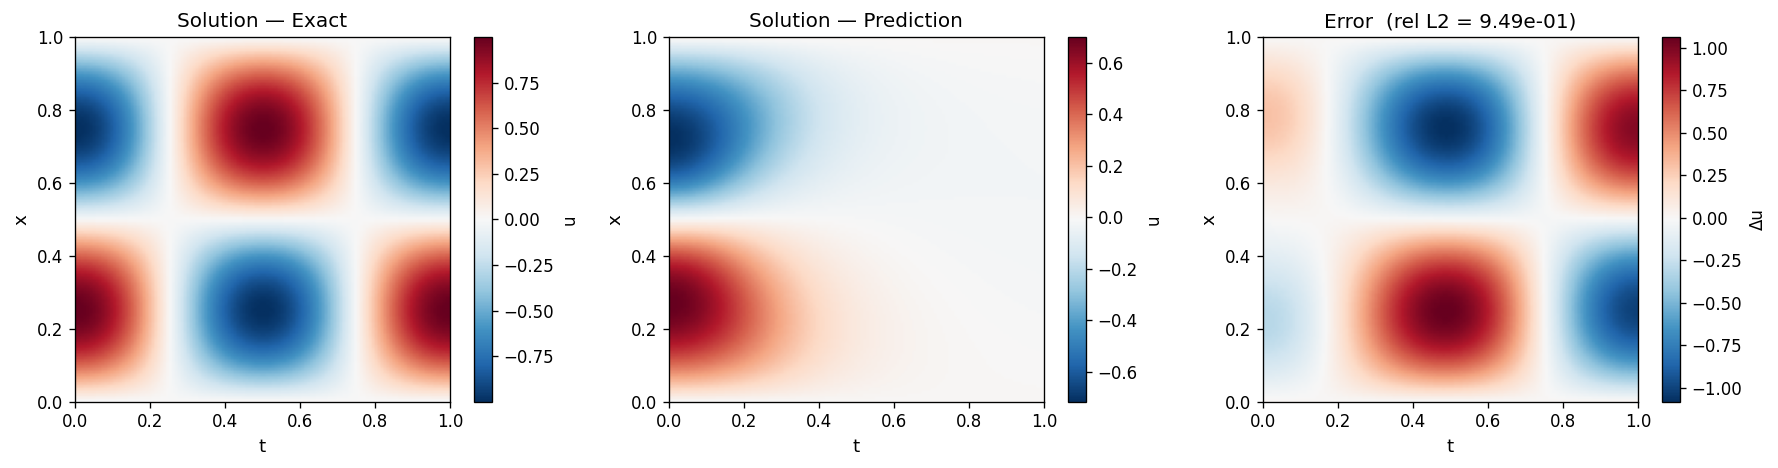

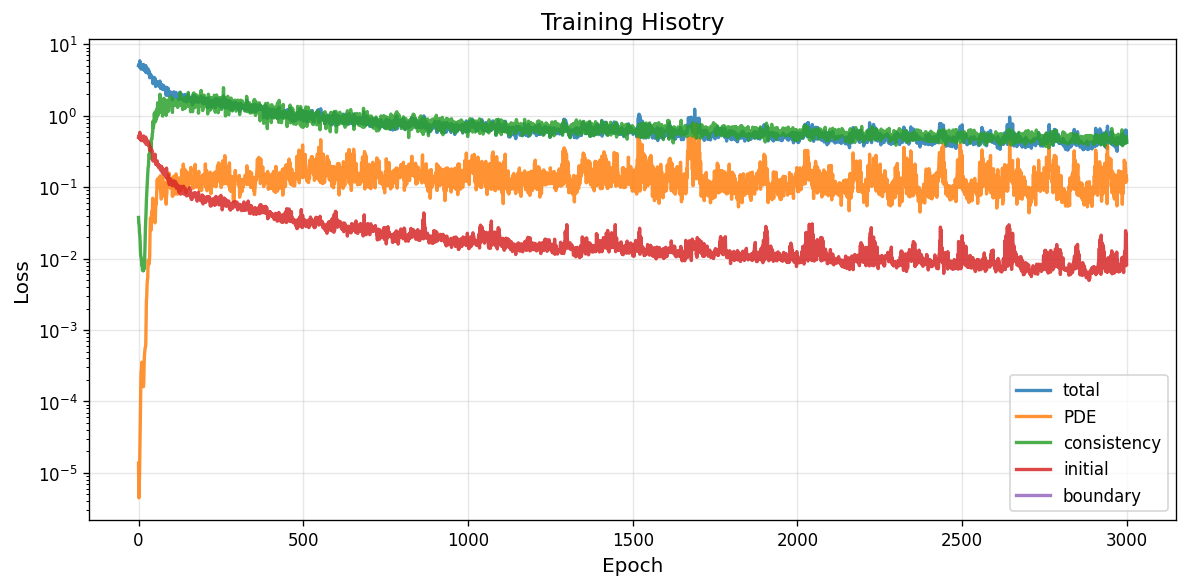

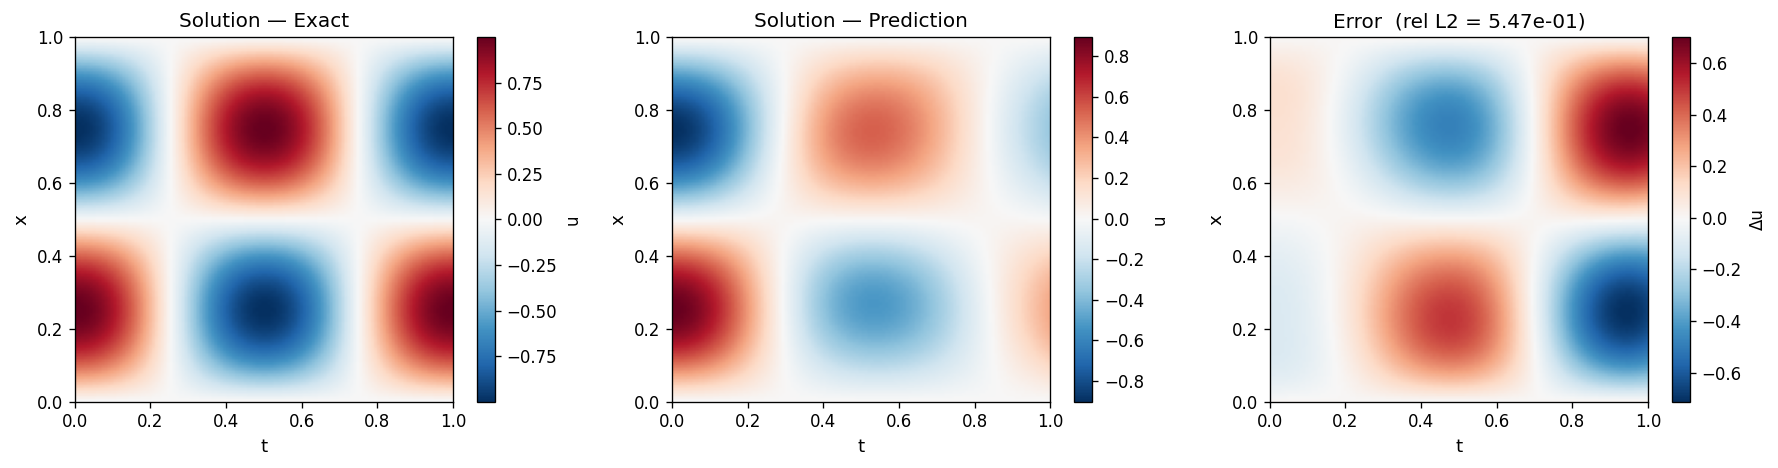

(<Figure size 1800x480 with 6 Axes>, 0.5471627116203308)

In [68]:
plot_training_history(history_q)
plot_solution_comparison(U_pred_q,U_true, x_grid, t_grid)
plot_training_history(history_c)
plot_solution_comparison(U_pred_c,U_true, x_grid, t_grid)
plot_training_history(history_qpinn_weights)
plot_solution_comparison(U_pred_q_w,U_true, x_grid, t_grid)


### 2.1 - Compare power spectra

QPINN power spectrum
Saved: ../figures/demo_fourier/power_spectrum_q.png


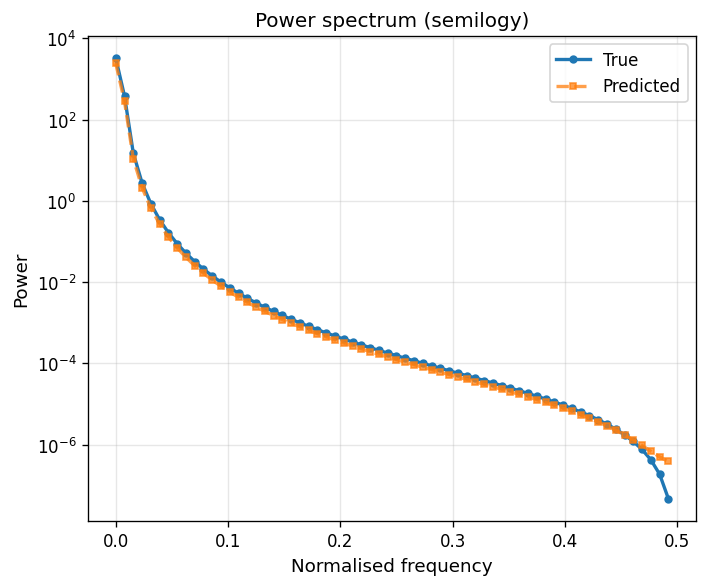

Classical power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


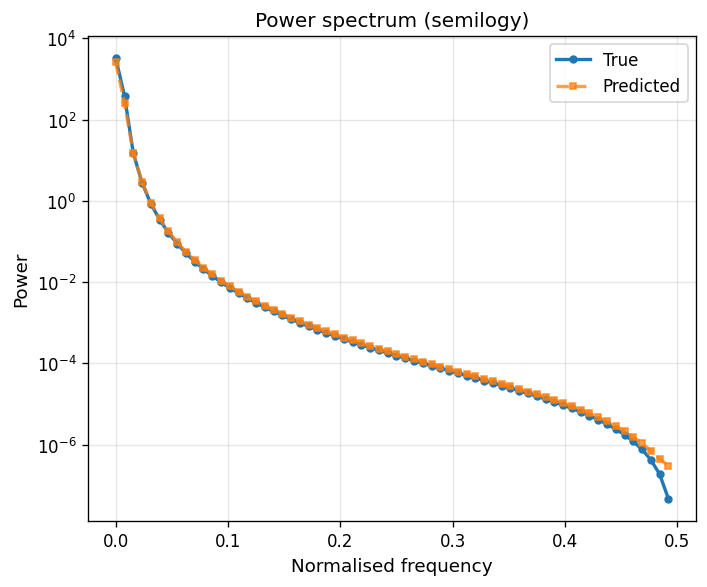

QPINN_weights power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


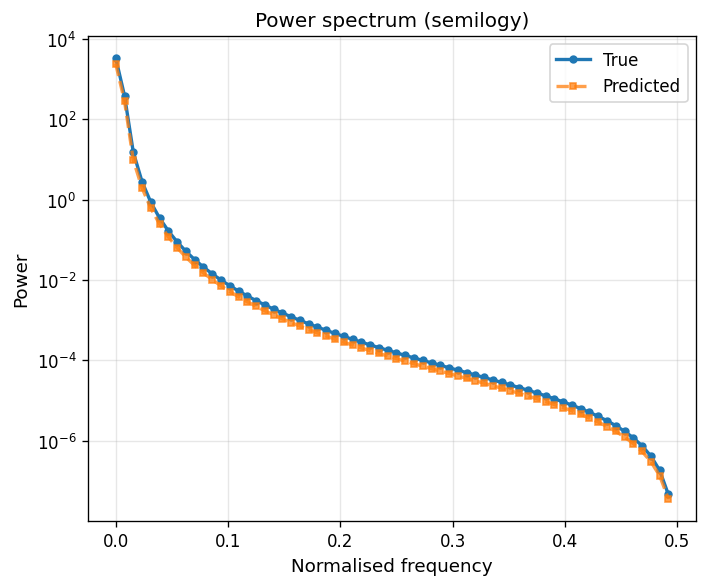

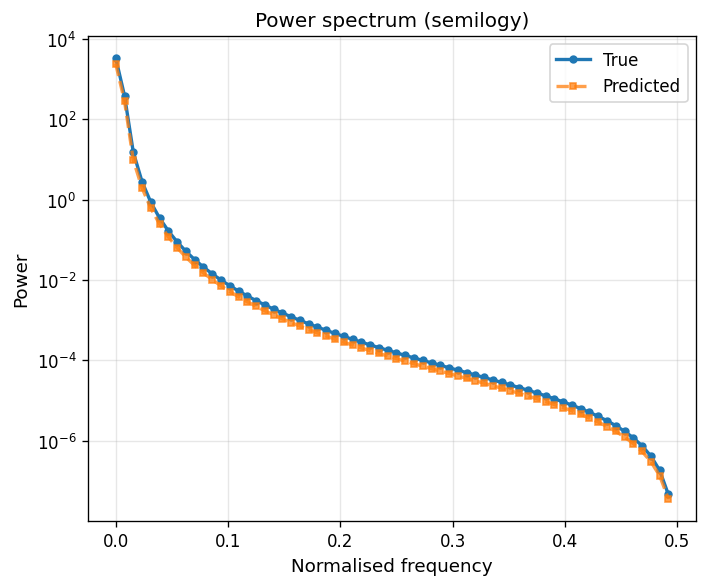

In [31]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

print("QPINN_weights power spectrum")
plot_power_spectrum(U_pred_q_w, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

QPINN mode errors
Saved: ../figures/fourier_demo/l2_error_Q.png


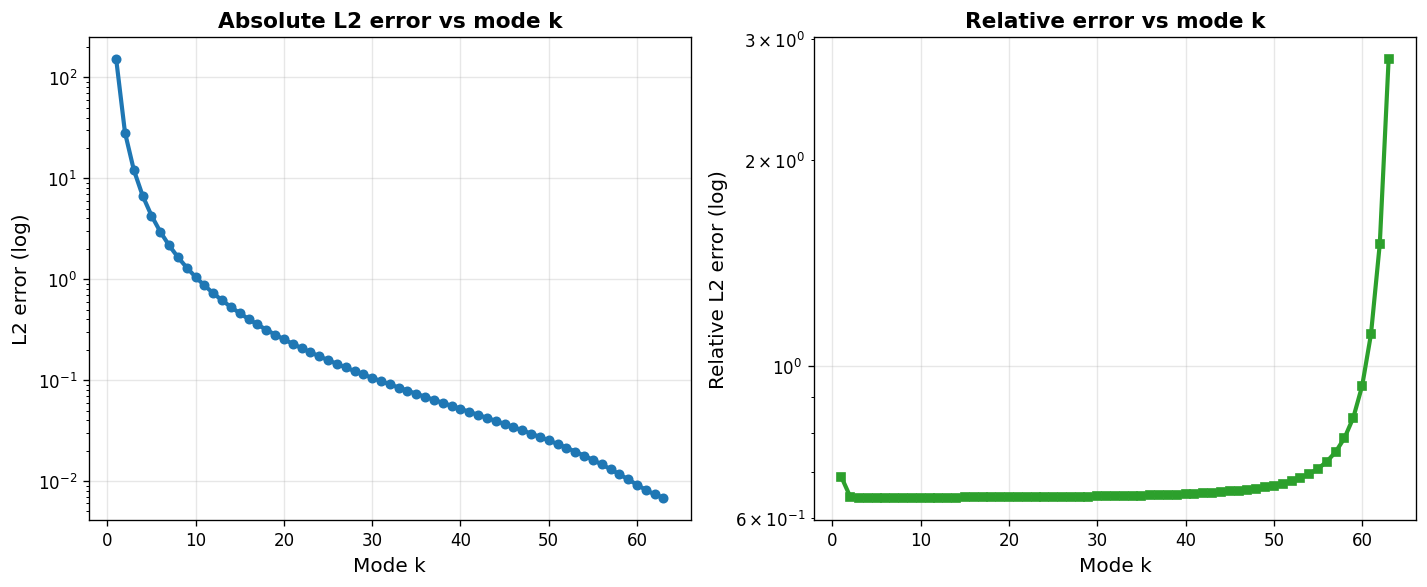

Classical mode errors
Saved: ../figures/fourier_demo/l2_error_C.png


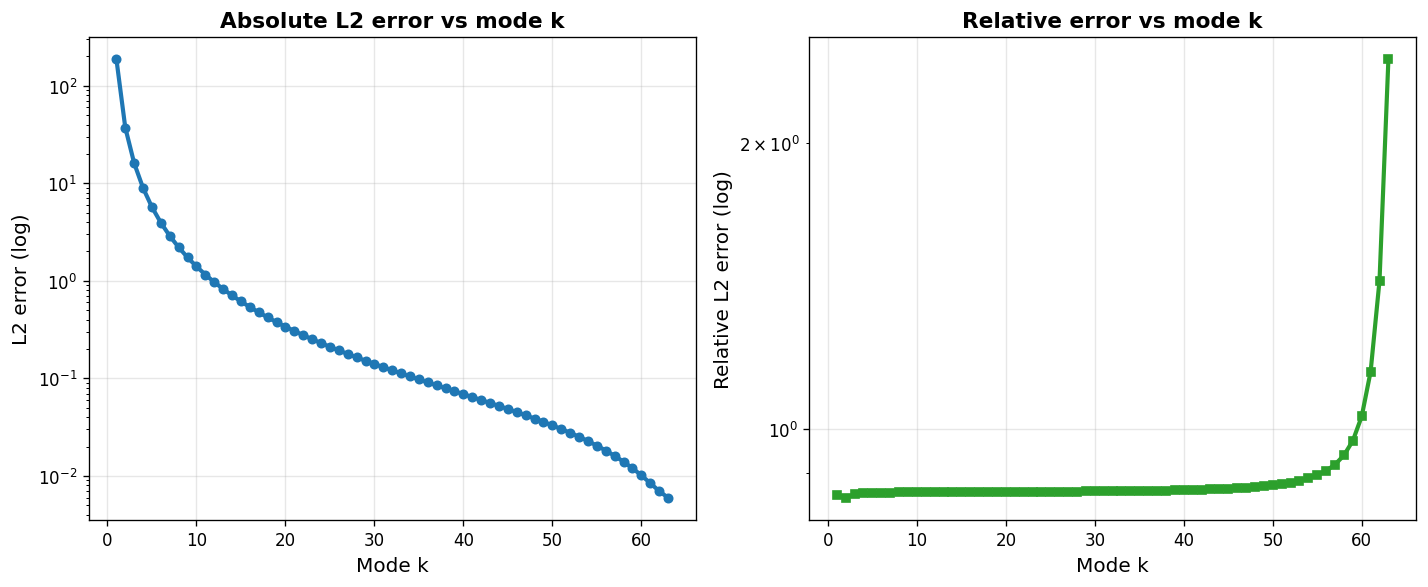

QPINN_weights mode errors
Saved: ../figures/fourier_demo/l2_error_Q_weights.png


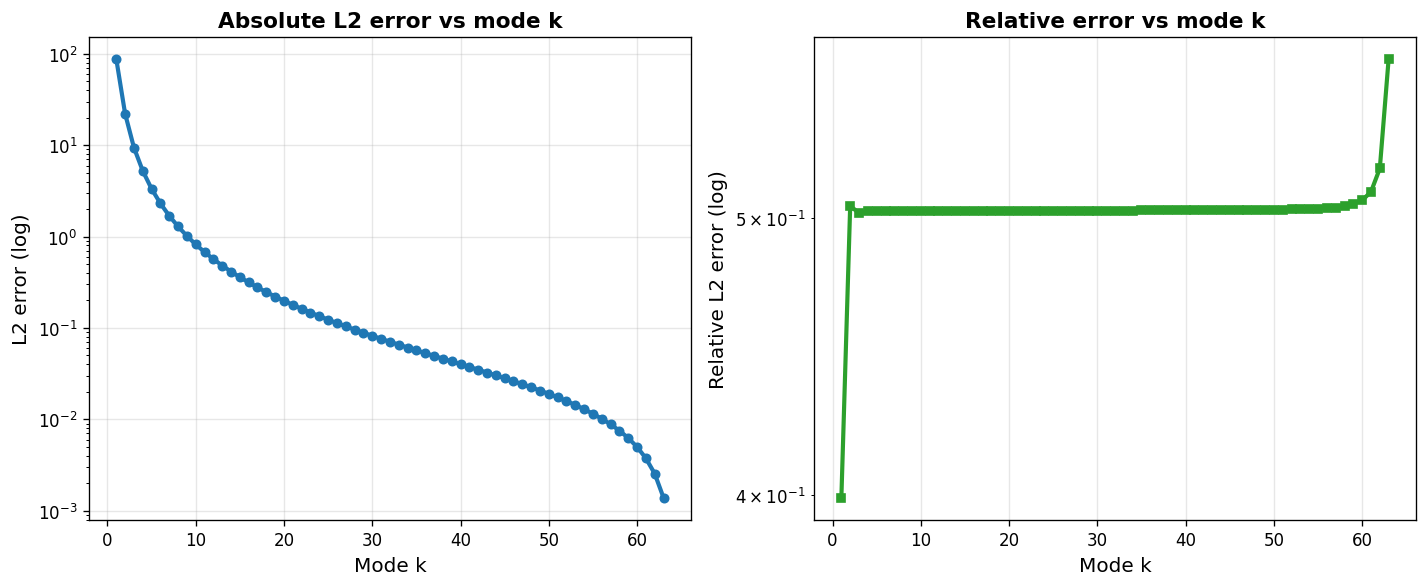

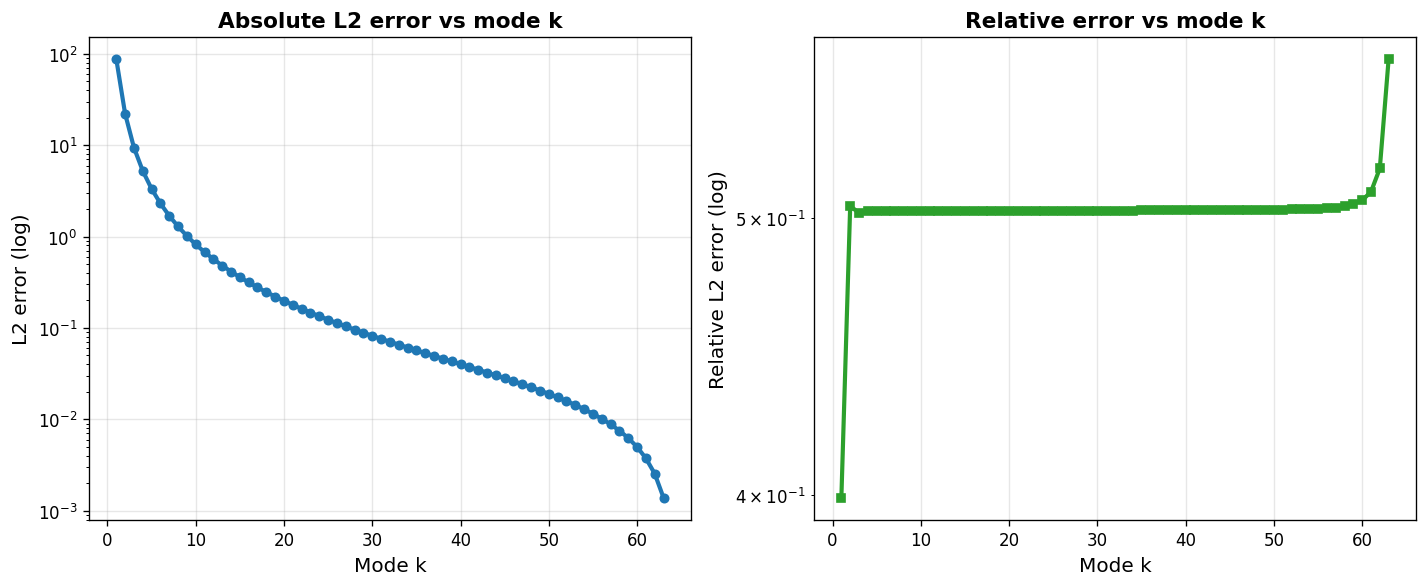

In [32]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="../figures/fourier_demo/l2_error_C.png")

print("QPINN_weights mode errors")
plot_mode_l2_errors(U_pred_q_w, U_true,
                    save_path="../figures/fourier_demo/l2_error_Q_weights.png")



## Compare directly

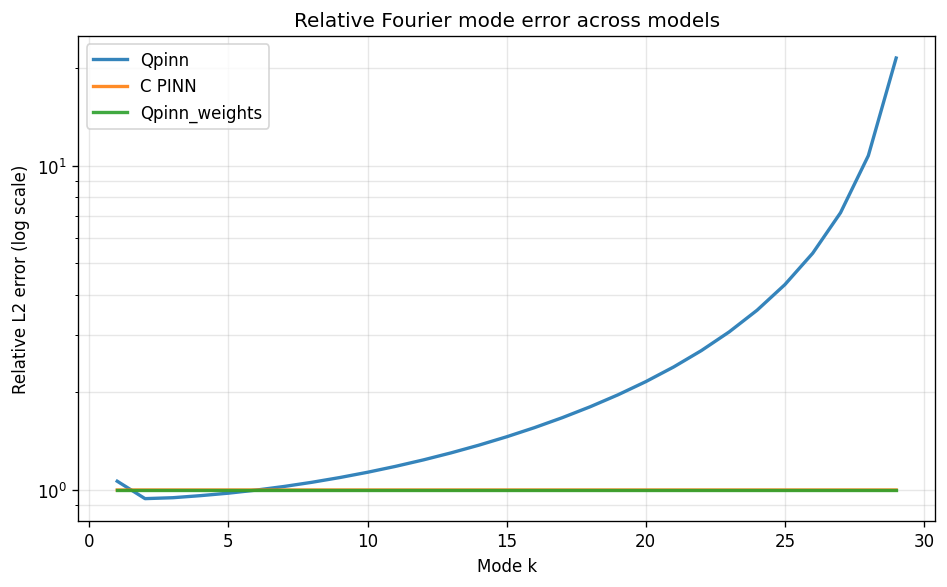

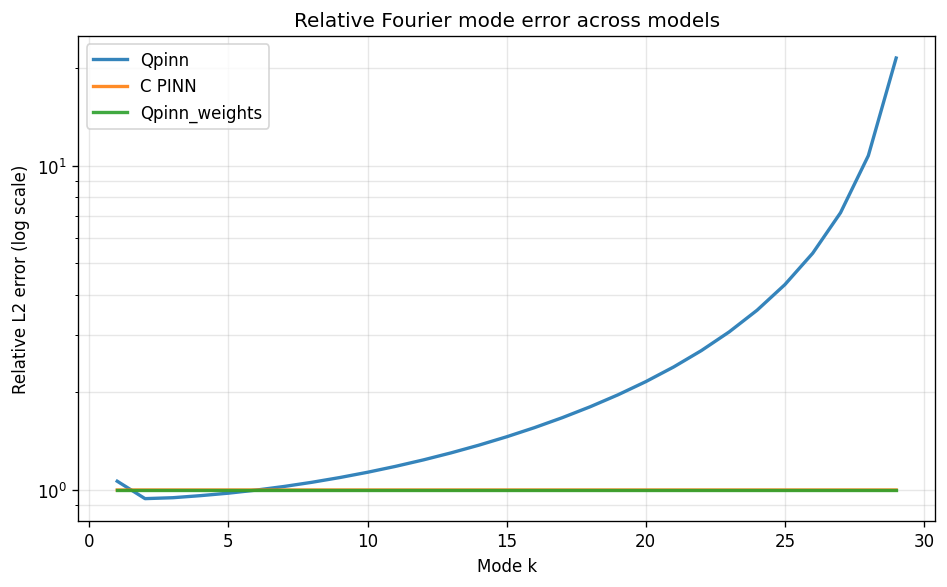

In [16]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c,U_pred_q_w],["Qpinn", "C PINN","Qpinn_weights"])